# Resultados

<div style="text-align: justify;">

Este _notebook_ analiza los resultados generados por `Ejecuciones.ipynb` (historial `historial_ejecuciones.csv` y frentes F0 en `.npz` dentro de `Results/Ejecuciones`).

</div>

In [ ]:
# 1. Clonar el repo
#!git clone https://github.com/BenjaminGonzalezH/Thesis.git /content/Thesis

# 2. Montar Drive
#from google.colab import drive
#drive.mount('/content/drive')


## Preparación del ambiente y lectura de resultados

In [2]:
#######################################################
# MODULO DE PREPARACIÓN DEL AMBIENTE Y LECTURA DE RESULTADOS
# Detección de entorno (Colab / Local), rutas del repositorio, restauración de
# los resultados desde Drive y lectura del historial de ejecuciones.
#######################################################

import os                                                   # Llamadas al SO.
import sys                                                  # Ajuste de sys.path para importar los módulos de Source Code.
import shutil                                               # Copia de archivos entre Drive y el disco local.
import numpy  as np                                         # Operaciones numéricas.
import pandas as pd                                         # Lectura del historial y resúmenes.
from pathlib import Path                                    # Formato generalizado de direcciones.

############################
# Detección de entorno (Colab / Local)
############################
try:
    import google.colab                                     # Módulo disponible solo dentro de runtimes de Colab.
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    THESIS_DIR = Path("/content/Thesis")
else:
    _cwd = Path(os.getcwd()).resolve()
    THESIS_DIR = next(
        (p for p in (_cwd, *_cwd.parents) if (p / "Datasets").is_dir() and (p / "Source Code").is_dir()),
        None,
    )
    if THESIS_DIR is None:
        raise FileNotFoundError(f"No se encontró la raíz del repositorio (Datasets/ y Source Code/) desde {_cwd}")
print(f"[entorno] {'Colab' if IN_COLAB else 'Local'} → {THESIS_DIR}")

SOURCE_CODE_DIR = THESIS_DIR / "Source Code"
if str(SOURCE_CODE_DIR) not in sys.path:
    sys.path.append(str(SOURCE_CODE_DIR))

############################
# Directorios de resultados y respaldo en Drive
############################
RESULTS_DIR = THESIS_DIR / "Results" / "Ejecuciones"       # Resultados generados por Ejecuciones.ipynb.
FRENTES_DIR = RESULTS_DIR / "Frentes"                      # Un .npz por ejecución (F0, medoides e historial de HV).
FRENTES_DIR.mkdir(parents=True, exist_ok=True)

DRIVE_RESULTS_DIR = Path("/content/drive/MyDrive/Thesis_Results/Ejecuciones")    # <-- ajusta a tu carpeta en Drive

def _copiar_arbol(origen: Path, destino: Path, restaurar: bool) -> None:
    """Copia recursiva de `origen` a `destino`. Con `restaurar`, no pisa archivos existentes; si no, solo copia lo nuevo o modificado."""
    if not origen.exists():
        return
    for archivo in origen.rglob("*"):
        if not archivo.is_file():
            continue
        objetivo = destino / archivo.relative_to(origen)
        if objetivo.exists() and (restaurar or objetivo.stat().st_mtime >= archivo.stat().st_mtime):
            continue
        objetivo.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(archivo, objetivo)

def sincronizar_drive(restaurar: bool = False) -> None:
    """Local -> Drive (o Drive -> local si `restaurar`). No hace nada fuera de Colab."""
    if not IN_COLAB:
        return
    try:
        if restaurar:
            _copiar_arbol(DRIVE_RESULTS_DIR, RESULTS_DIR, restaurar=True)
        else:
            _copiar_arbol(RESULTS_DIR, DRIVE_RESULTS_DIR, restaurar=False)
    except Exception as e:                                  # Un fallo de Drive no debe interrumpir el análisis.
        print(f"[drive] no se pudo {'restaurar' if restaurar else 'respaldar'}: {e}")

sincronizar_drive(restaurar=True)

############################
# Variantes y lectura del historial
############################
VARIANTES = ["NSGA2", "NSGA2_PLS", "NSGA2_MOLS", "NSGA2_DBS", "NSGA2_PNS", "NSGA2_MOPR"]   # Mismo orden que Ejecuciones.ipynb.
HISTORIAL_FILE = RESULTS_DIR / "historial_ejecuciones.csv"

def leer_historial() -> pd.DataFrame:
    return pd.read_csv(HISTORIAL_FILE) if HISTORIAL_FILE.exists() else pd.DataFrame()

_h = leer_historial()
print(f"[resultados] {RESULTS_DIR} | {len(_h)} ejecuciones en el historial")


[entorno] Local → C:\Users\benja\Desktop\workspace\Thesis
[resultados] C:\Users\benja\Desktop\workspace\Thesis\Results\Ejecuciones | 702 ejecuciones en el historial


## 5. Definición de Medidas Estadísticas Clave

Se realizan las separaciones de los datos de las ejecuciones por _dataset_ y variante del NSGA-II con la finalidad de establecer que métricas serán utilizadas para sacar las respectivas conclusiones sobre el rendimiento de los operadores propuestos, asimismo, se realizaran pruebas de normalidad para considerar el conjunto de pruebas necesarias para compararlas (test de Shapiro-Wilk, α = 0.05).

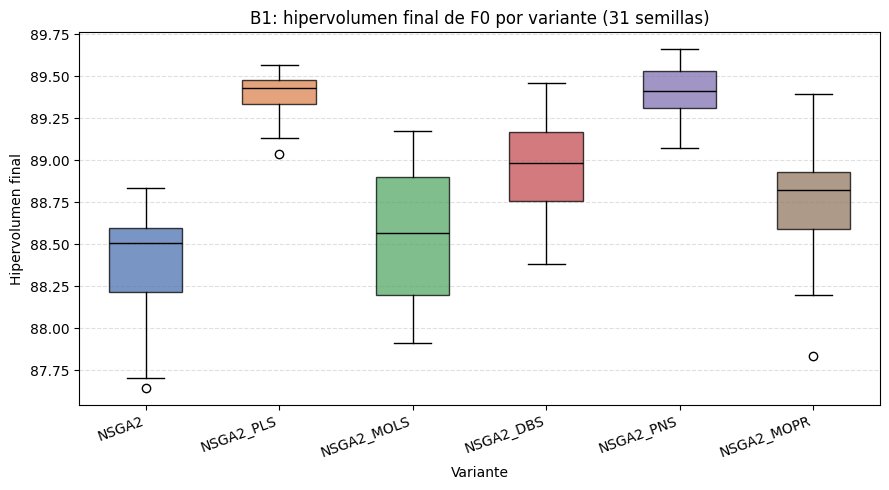

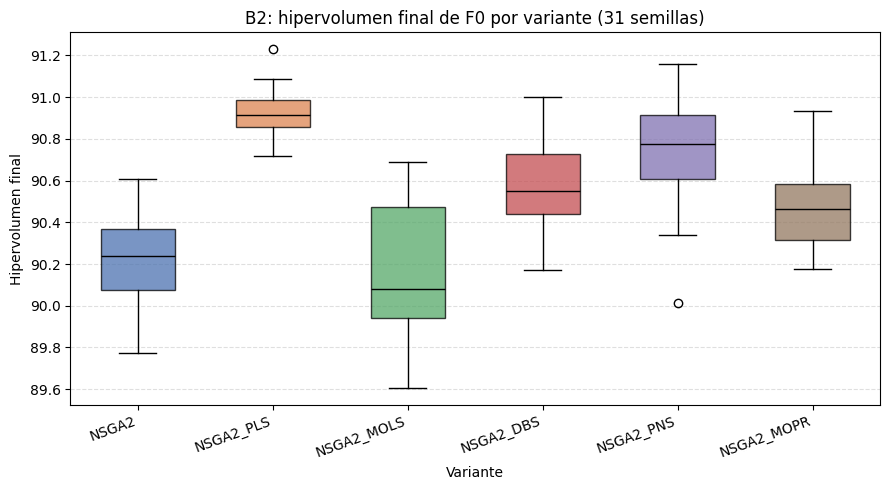

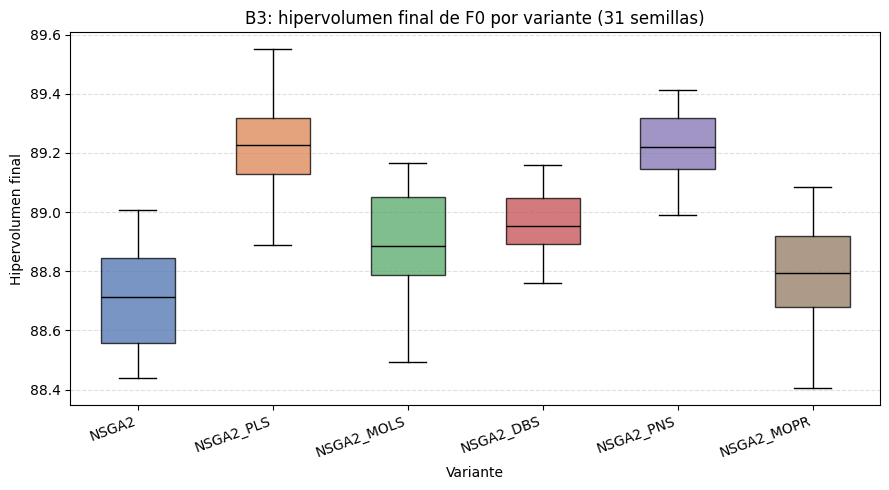

n  shapiro_w  p_valor normal (α=0.05)
dataset variante                                          
B1      NSGA2       31     0.8875   0.0036              no
        NSGA2_DBS   31     0.9665   0.4287              sí
        NSGA2_MOLS  31     0.9457   0.1191              sí
        NSGA2_MOPR  31     0.9662   0.4220              sí
        NSGA2_PLS   31     0.9046   0.0094              no
        NSGA2_PNS   31     0.9679   0.4637              sí
B2      NSGA2       31     0.9806   0.8304              sí
        NSGA2_DBS   31     0.9744   0.6457              sí
        NSGA2_MOLS  31     0.9260   0.0341              no
        NSGA2_MOPR  31     0.9465   0.1251              sí
        NSGA2_PLS   31     0.9701   0.5209              sí
        NSGA2_PNS   31     0.9319   0.0494              no
B3      NSGA2       31     0.9407   0.0861              sí
        NSGA2_DBS   31     0.9780   0.7543              sí
        NSGA2_MOLS  31     0.9447   0.1111              sí
        NSGA2_MOPR  31     0.9767   0.7153              sí
        NSGA2_PLS   31     0.9940   0.9997              sí
        NSGA2_PNS   31     0.9699   0.5158              sí


[normalidad] 4 de 18 conjuntos (dataset × variante) no superan Shapiro-Wilk con α=0.05.


In [ ]:
#######################################################
# MODULO ASOCIADO A COMPARAR LOS PROMEDIOS DE HV (10, 10) 
# DE CADA F0 DENTRO DE LAS EJECUCIONES.
#######################################################

import matplotlib.pyplot as plt
from scipy import stats

historial = leer_historial()
if historial.empty:
    print("Aún no hay ejecuciones registradas.")
else:
    ultimas = historial.sort_values("fecha").drop_duplicates(["variante", "dataset", "semilla"], keep="last")

    # Orden fijo de variantes y colores categóricos (mismo orden en los 3 boxplots).
    ORDEN_VARIANTES = list(VARIANTES)
    COLORES_VARIANTES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860"]

    datasets = sorted(ultimas["dataset"].unique())
    for nombre_ds in datasets:
        datos_ds = ultimas[ultimas["dataset"] == nombre_ds]
        grupos = [datos_ds.loc[datos_ds["variante"] == v, "hv_final"].to_numpy() for v in ORDEN_VARIANTES]
        tamanos = {v: len(g) for v, g in zip(ORDEN_VARIANTES, grupos)}
        if any(n != 31 for n in tamanos.values()):
            print(f"[{nombre_ds}] aviso: no todas las variantes tienen 31 ejecuciones -> {tamanos}")

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = ax.boxplot(grupos, tick_labels=ORDEN_VARIANTES, patch_artist=True, widths=0.55)
        for patch, color in zip(bp["boxes"], COLORES_VARIANTES):
            patch.set_facecolor(color)
            patch.set_alpha(0.75)
        for mediana in bp["medians"]:
            mediana.set_color("black")
        ax.set_title(f"{nombre_ds}: hipervolumen final de F0 por variante (31 semillas)")
        ax.set_xlabel("Variante")
        ax.set_ylabel("Hipervolumen final")
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
        fig.tight_layout()
        plt.show()

    # Test de Shapiro-Wilk por cada combinación dataset x variante (31 ejecuciones).
    filas_normalidad = []
    for (nombre_ds, variante), g in ultimas.groupby(["dataset", "variante"]):
        valores = g["hv_final"].to_numpy()
        estadistico, p_valor = stats.shapiro(valores)
        filas_normalidad.append({
            "dataset": nombre_ds, "variante": variante, "n": len(valores),
            "shapiro_w": round(float(estadistico), 4), "p_valor": round(float(p_valor), 4),
            "normal (α=0.05)": "sí" if p_valor > 0.05 else "no",
        })
    normalidad = (pd.DataFrame(filas_normalidad)
                  .sort_values(["dataset", "variante"])
                  .set_index(["dataset", "variante"]))
    normalidad.to_csv(RESULTS_DIR / "normalidad_shapiro.csv")
    sincronizar_drive()
    display(normalidad)

    n_no_normales = (normalidad["normal (α=0.05)"] == "no").sum()
    print(f"\n[normalidad] {n_no_normales} de {len(normalidad)} conjuntos (dataset × variante) "
          f"no superan Shapiro-Wilk con α=0.05.")

[B1] frente de referencia: 24 soluciones no dominadas (de 2692 en 186 frentes F0)
[B2] frente de referencia: 35 soluciones no dominadas (de 3051 en 186 frentes F0)
[B3] frente de referencia: 26 soluciones no dominadas (de 4566 en 186 frentes F0)


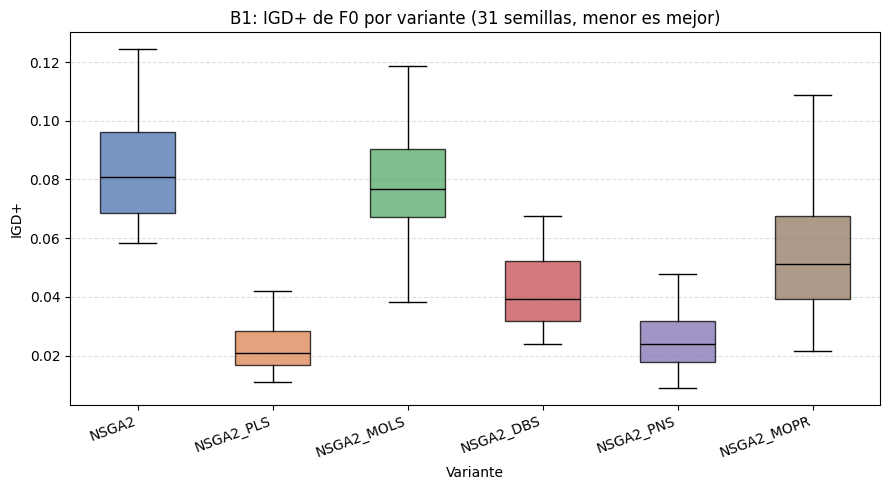

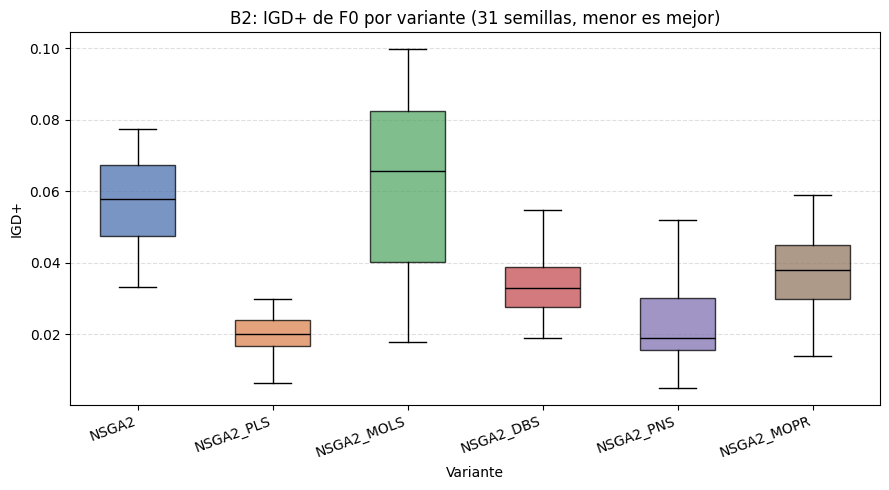

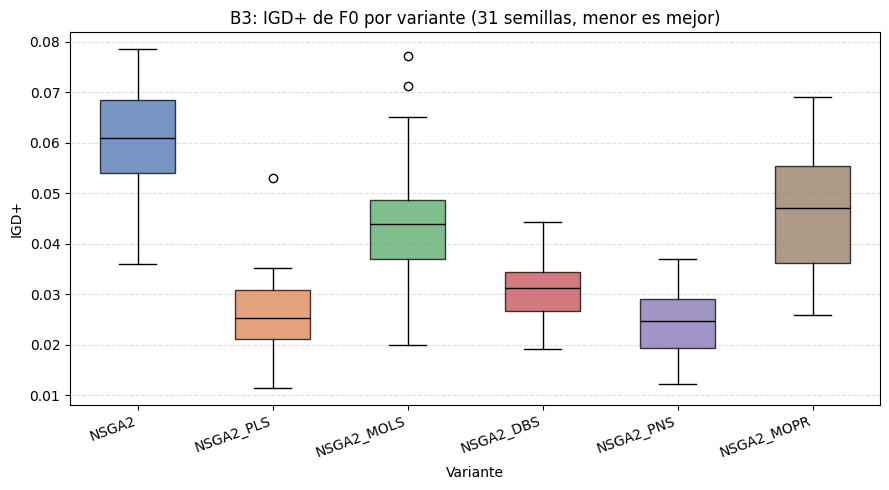

n   media    desv  minimo  mediana  maximo
dataset variante                                               
B1      NSGA2       31  0.0844  0.0197  0.0582   0.0807  0.1244
        NSGA2_DBS   31  0.0419  0.0134  0.0241   0.0392  0.0674
        NSGA2_MOLS  31  0.0788  0.0204  0.0382   0.0768  0.1187
        NSGA2_MOPR  31  0.0550  0.0201  0.0216   0.0513  0.1086
        NSGA2_PLS   31  0.0229  0.0083  0.0110   0.0209  0.0419
        NSGA2_PNS   31  0.0255  0.0094  0.0090   0.0238  0.0479
B2      NSGA2       31  0.0574  0.0122  0.0332   0.0577  0.0774
        NSGA2_DBS   31  0.0336  0.0082  0.0190   0.0329  0.0549
        NSGA2_MOLS  31  0.0617  0.0248  0.0180   0.0655  0.0997
        NSGA2_MOPR  31  0.0378  0.0118  0.0141   0.0381  0.0588
        NSGA2_PLS   31  0.0196  0.0060  0.0065   0.0200  0.0300
        NSGA2_PNS   31  0.0229  0.0112  0.0051   0.0190  0.0519
B3      NSGA2       31  0.0607  0.0097  0.0360   0.0608  0.0785
        NSGA2_DBS   31  0.0311  0.0062  0.0193   0.0312  0.0443
        NSGA2_MOLS  31  0.0442  0.0125  0.0199   0.0439  0.0771
        NSGA2_MOPR  31  0.0461  0.0121  0.0259   0.0471  0.0690
        NSGA2_PLS   31  0.0262  0.0078  0.0115   0.0254  0.0531
        NSGA2_PNS   31  0.0245  0.0068  0.0122   0.0247  0.0369

n  shapiro_w  p_valor normal (α=0.05)
dataset variante                                          
B1      NSGA2       31     0.9206   0.0245              no
        NSGA2_DBS   31     0.9252   0.0325              no
        NSGA2_MOLS  31     0.9745   0.6508              sí
        NSGA2_MOPR  31     0.9507   0.1637              sí
        NSGA2_PLS   31     0.9417   0.0918              sí
        NSGA2_PNS   31     0.9632   0.3540              sí
B2      NSGA2       31     0.9656   0.4079              sí
        NSGA2_DBS   31     0.9695   0.5042              sí
        NSGA2_MOLS  31     0.9407   0.0862              sí
        NSGA2_MOPR  31     0.9757   0.6873              sí
        NSGA2_PLS   31     0.9655   0.4046              sí
        NSGA2_PNS   31     0.9452   0.1147              sí
B3      NSGA2       31     0.9811   0.8414              sí
        NSGA2_DBS   31     0.9852   0.9353              sí
        NSGA2_MOLS  31     0.9530   0.1894              sí
        NSGA2_MOPR  31     0.9714   0.5594              sí
        NSGA2_PLS   31     0.9294   0.0423              no
        NSGA2_PNS   31     0.9699   0.5159              sí

[normalidad IGD+] 3 de 18 conjuntos (dataset × variante) no superan Shapiro-Wilk con α=0.05.


In [5]:
#######################################################
# MODULO DE CONSTRUCCIÓN Y COMPARACIÓN DE VARIANTES POR
# IGD+
#######################################################
# Nota: Se debe construir el frente no dominado considerando
# las soluciones no dominada de todos los frentes considerando
# aquellos asociados al dataset
#
# Por dataset: frente de referencia Z = soluciones no dominadas de la unión de
# todos los F0 (todas las variantes y semillas). Luego se calcula el IGD+ de cada
# F0 respecto a Z (MENOR es mejor), boxplot por variante y Shapiro-Wilk por
# (dataset, variante), igual que en el estudio de hipervolumen.
#######################################################

import matplotlib.pyplot as plt
from scipy import stats

def filtrar_no_dominadas(puntos: np.ndarray) -> np.ndarray:
    """Soluciones no dominadas (minimización) de un conjunto de puntos; descarta no finitos y duplicados."""
    pts = np.unique(np.asarray(puntos, dtype=np.float64).reshape(-1, 2), axis=0)
    pts = pts[np.isfinite(pts).all(axis=1)]
    orden = pts[np.lexsort((pts[:, 1], pts[:, 0]))]          # XB_GE creciente, desempate por XB_BI.
    mejor_bi, no_dom = np.inf, []
    for ge, bi in orden:
        if bi < mejor_bi:                                    # Solo entra si mejora el mejor XB_BI visto.
            no_dom.append((ge, bi))
            mejor_bi = bi
    return np.array(no_dom)

def igd_plus(aproximacion: np.ndarray, referencia: np.ndarray) -> float:
    """IGD+ (Ishibuchi et al., 2015): media sobre z de Z de min_a sqrt(sum(max(a - z, 0)^2)). MENOR es mejor."""
    a = np.asarray(aproximacion, dtype=np.float64).reshape(-1, 2)
    a = a[np.isfinite(a).all(axis=1)]
    if len(a) == 0:
        return float("inf")
    dif = np.maximum(a[None, :, :] - referencia[:, None, :], 0.0)    # (|Z|, |A|, 2)
    return float(np.sqrt((dif ** 2).sum(axis=2)).min(axis=1).mean())

historial = leer_historial()
if historial.empty:
    print("Aún no hay ejecuciones registradas.")
else:
    ultimas = historial.sort_values("fecha").drop_duplicates(["variante", "dataset", "semilla"], keep="last")
    ORDEN_VARIANTES = list(VARIANTES)
    COLORES_VARIANTES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860"]

    # Índice de los .npz (tolera subcarpetas anidadas, p. ej. Frentes/Frentes).
    indice_npz = {p.name: p for p in FRENTES_DIR.rglob("*.npz")}

    # 1) Objetivos de cada F0 y frente de referencia por dataset.
    frentes, referencias, faltantes = {}, {}, []
    for nombre_ds, g in ultimas.groupby("dataset"):
        union = []
        for fila in g.itertuples():
            archivo = indice_npz.get(f"{fila.variante}_{fila.dataset}_{fila.semilla}.npz")
            if archivo is None:
                faltantes.append(f"{fila.variante}_{fila.dataset}_{fila.semilla}")
                continue
            with np.load(archivo) as d:
                obj = np.asarray(d["objectives"], dtype=np.float64).reshape(-1, 2)
            frentes[(fila.variante, fila.dataset, fila.semilla)] = obj
            union.append(obj)
        if union:
            referencias[nombre_ds] = filtrar_no_dominadas(np.vstack(union))
            print(f"[{nombre_ds}] frente de referencia: {len(referencias[nombre_ds])} soluciones no dominadas "
                  f"(de {sum(len(u) for u in union)} en {len(union)} frentes F0)")
    if faltantes:
        print(f"[aviso] {len(faltantes)} frentes .npz no encontrados en {FRENTES_DIR} (se omiten): {faltantes[:3]} ...")

    # 2) IGD+ de cada ejecución respecto a la referencia de su dataset.
    ultimas = ultimas[[(v, d, s) in frentes for v, d, s in zip(ultimas["variante"], ultimas["dataset"], ultimas["semilla"])]].copy()
    ultimas["igd_plus"] = [igd_plus(frentes[(v, d, s)], referencias[d])
                           for v, d, s in zip(ultimas["variante"], ultimas["dataset"], ultimas["semilla"])]
    igd_ejecuciones = ultimas[["dataset", "variante", "semilla", "hv_final", "igd_plus"]]
    igd_ejecuciones.to_csv(RESULTS_DIR / "igd_plus_ejecuciones.csv", index=False)

    # 3) Boxplot por dataset (mismo orden y colores que en HV).
    for nombre_ds in sorted(referencias):
        datos_ds = ultimas[ultimas["dataset"] == nombre_ds]
        grupos = [datos_ds.loc[datos_ds["variante"] == v, "igd_plus"].to_numpy() for v in ORDEN_VARIANTES]
        tamanos = {v: len(g) for v, g in zip(ORDEN_VARIANTES, grupos)}
        if any(n != 31 for n in tamanos.values()):
            print(f"[{nombre_ds}] aviso: no todas las variantes tienen 31 ejecuciones -> {tamanos}")

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = ax.boxplot(grupos, tick_labels=ORDEN_VARIANTES, patch_artist=True, widths=0.55)
        for patch, color in zip(bp["boxes"], COLORES_VARIANTES):
            patch.set_facecolor(color)
            patch.set_alpha(0.75)
        for mediana in bp["medians"]:
            mediana.set_color("black")
        ax.set_title(f"{nombre_ds}: IGD+ de F0 por variante (31 semillas, menor es mejor)")
        ax.set_xlabel("Variante")
        ax.set_ylabel("IGD+")
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
        fig.tight_layout()
        plt.show()

    # 4) Resumen y Shapiro-Wilk por dataset x variante.
    resumen_igd = (ultimas.groupby(["dataset", "variante"])["igd_plus"]
                   .agg(n="size", media="mean", desv="std", minimo="min", mediana="median", maximo="max").round(4))
    resumen_igd.to_csv(RESULTS_DIR / "resumen_igd_plus.csv")
    display(resumen_igd)

    filas_normalidad = []
    for (nombre_ds, variante), g in ultimas.groupby(["dataset", "variante"]):
        valores = g["igd_plus"].to_numpy()
        estadistico, p_valor = stats.shapiro(valores)
        filas_normalidad.append({
            "dataset": nombre_ds, "variante": variante, "n": len(valores),
            "shapiro_w": round(float(estadistico), 4), "p_valor": round(float(p_valor), 4),
            "normal (α=0.05)": "sí" if p_valor > 0.05 else "no",
        })
    normalidad_igd = (pd.DataFrame(filas_normalidad).sort_values(["dataset", "variante"]).set_index(["dataset", "variante"]))
    normalidad_igd.to_csv(RESULTS_DIR / "normalidad_shapiro_igd_plus.csv")
    sincronizar_drive()
    display(normalidad_igd)

    n_no_normales = (normalidad_igd["normal (α=0.05)"] == "no").sum()
    print(f"[normalidad IGD+] {n_no_normales} de {len(normalidad_igd)} conjuntos (dataset × variante) no superan Shapiro-Wilk con α=0.05.")


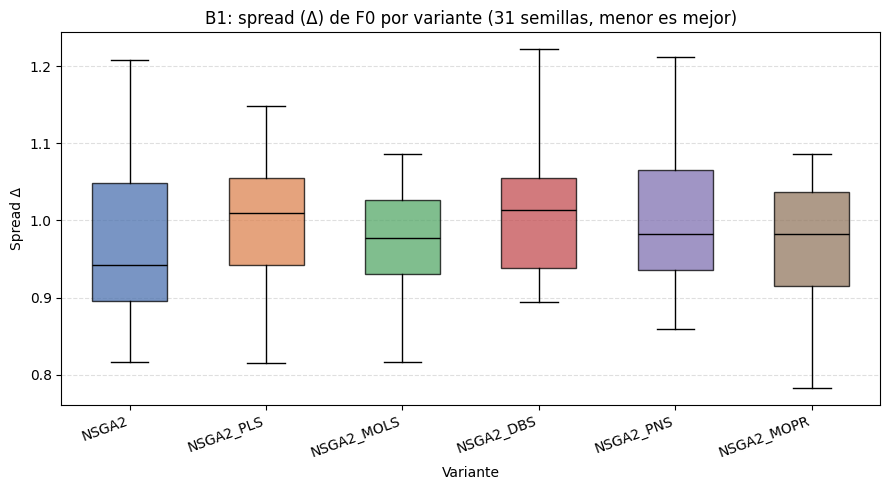

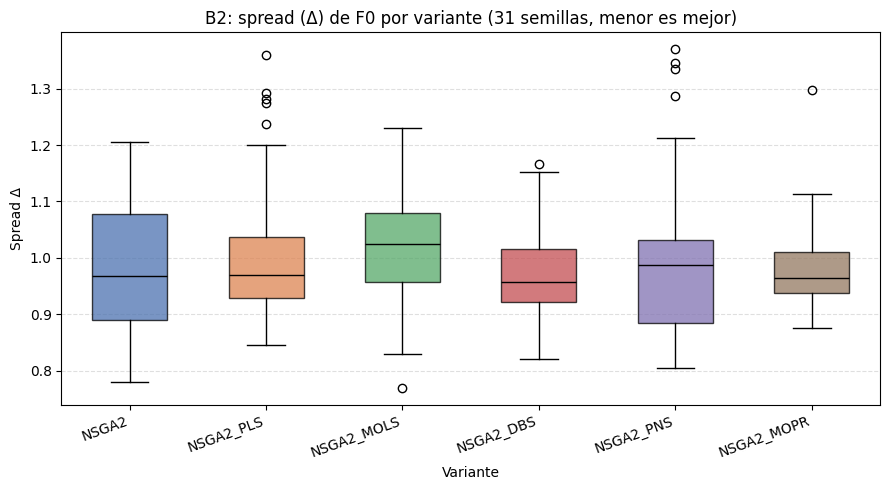

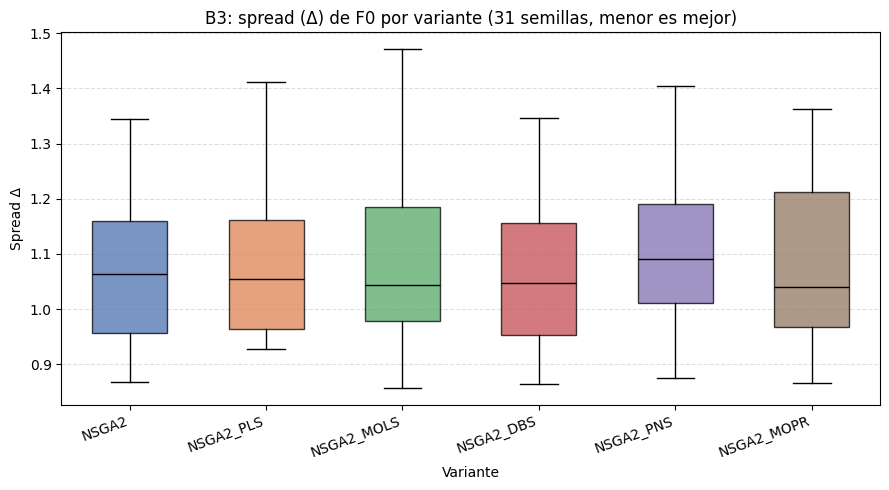

n   media    desv  minimo  mediana  maximo
dataset variante                                               
B1      NSGA2       31  0.9717  0.1046  0.8168   0.9424  1.2085
        NSGA2_DBS   31  1.0129  0.0876  0.8943   1.0141  1.2221
        NSGA2_MOLS  31  0.9708  0.0714  0.8165   0.9771  1.0862
        NSGA2_MOPR  31  0.9709  0.0729  0.7829   0.9822  1.0859
        NSGA2_PLS   31  0.9973  0.0822  0.8146   1.0095  1.1488
        NSGA2_PNS   31  1.0033  0.0918  0.8589   0.9826  1.2115
B2      NSGA2       31  0.9864  0.1161  0.7808   0.9677  1.2060
        NSGA2_DBS   31  0.9702  0.0806  0.8201   0.9572  1.1656
        NSGA2_MOLS  31  1.0195  0.1009  0.7696   1.0249  1.2301
        NSGA2_MOPR  31  0.9805  0.0802  0.8750   0.9641  1.2969
        NSGA2_PLS   31  1.0205  0.1386  0.8450   0.9699  1.3598
        NSGA2_PNS   31  1.0011  0.1562  0.8051   0.9877  1.3698
B3      NSGA2       31  1.0682  0.1412  0.8677   1.0639  1.3455
        NSGA2_DBS   31  1.0666  0.1384  0.8640   1.0470  1.3466
        NSGA2_MOLS  31  1.0839  0.1443  0.8573   1.0442  1.4711
        NSGA2_MOPR  31  1.0834  0.1471  0.8656   1.0398  1.3624
        NSGA2_PLS   31  1.0855  0.1416  0.9279   1.0539  1.4120
        NSGA2_PNS   31  1.0985  0.1323  0.8751   1.0914  1.4046

n  shapiro_w  p_valor normal (α=0.05)
dataset variante                                          
B1      NSGA2       31     0.9384   0.0745              sí
        NSGA2_DBS   31     0.9467   0.1263              sí
        NSGA2_MOLS  31     0.9693   0.4994              sí
        NSGA2_MOPR  31     0.9625   0.3399              sí
        NSGA2_PLS   31     0.9789   0.7800              sí
        NSGA2_PNS   31     0.9569   0.2410              sí
B2      NSGA2       31     0.9461   0.1218              sí
        NSGA2_DBS   31     0.9264   0.0351              no
        NSGA2_MOLS  31     0.9900   0.9902              sí
        NSGA2_MOPR  31     0.8313   0.0002              no
        NSGA2_PLS   31     0.8103   0.0001              no
        NSGA2_PNS   31     0.8529   0.0006              no
B3      NSGA2       31     0.9478   0.1361              sí
        NSGA2_DBS   31     0.9402   0.0838              sí
        NSGA2_MOLS  31     0.9550   0.2139              sí
        NSGA2_MOPR  31     0.9233   0.0289              no
        NSGA2_PLS   31     0.8936   0.0050              no
        NSGA2_PNS   31     0.9738   0.6277              sí

[normalidad spread] 6 de 18 conjuntos (dataset × variante) no superan Shapiro-Wilk con α=0.05.


In [7]:
#######################################################
# MODULO DE SPREAD (Δ DE DEB) PARA LA DIVERSIDAD DEL FRENTE
#######################################################
# Por dataset: spread de cada F0 respecto al frente de referencia construido en
# el módulo de IGD+ (soluciones no dominadas de la unión de todos los F0).
#   Δ = (d_f + d_l + Σ|d_i − d̄|) / (d_f + d_l + (N−1)·d̄)
# d_i: distancia euclídea entre soluciones consecutivas del F0 (ordenado por
# XB_GE), d̄: su media, d_f y d_l: distancia entre los extremos del frente de
# referencia y los extremos del F0. MENOR es mejor (0 = distribución uniforme
# que cubre los extremos). Requiere haber ejecutado antes el módulo de IGD+.
#######################################################

import matplotlib.pyplot as plt
from scipy import stats

NORMALIZAR_SPREAD = True        # Escala cada objetivo al rango del frente de referencia (evita que domine el de mayor escala).

def spread_deb(aproximacion: np.ndarray, referencia: np.ndarray) -> float:
    """Δ de Deb para dos objetivos (minimización). MENOR es mejor; un frente de una sola solución vale 1."""
    a = np.unique(np.asarray(aproximacion, dtype=np.float64).reshape(-1, 2), axis=0)
    a = a[np.isfinite(a).all(axis=1)]
    if len(a) == 0:
        return float("nan")
    a = a[np.argsort(a[:, 0], kind="stable")]
    ref = referencia[np.argsort(referencia[:, 0], kind="stable")]
    d_f = np.linalg.norm(a[0] - ref[0])                      # Extremo con menor XB_GE.
    d_l = np.linalg.norm(a[-1] - ref[-1])                    # Extremo con menor XB_BI.
    if len(a) == 1:
        return 1.0
    d = np.linalg.norm(np.diff(a, axis=0), axis=1)
    d_med = d.mean()
    denominador = d_f + d_l + len(d) * d_med
    return float((d_f + d_l + np.abs(d - d_med).sum()) / denominador) if denominador > 0 else 0.0

if "referencias" not in globals() or "frentes" not in globals():
    print("Primero ejecuta el módulo de IGD+ (define `frentes` y `referencias`).")
else:
    historial = leer_historial()
    ultimas_sp = historial.sort_values("fecha").drop_duplicates(["variante", "dataset", "semilla"], keep="last")
    ultimas_sp = ultimas_sp[[(v, d, s) in frentes for v, d, s in
                             zip(ultimas_sp["variante"], ultimas_sp["dataset"], ultimas_sp["semilla"])]].copy()

    def _escalar(puntos, ref):
        if not NORMALIZAR_SPREAD:
            return puntos
        minimo = ref.min(axis=0)
        rango = np.where(ref.max(axis=0) > minimo, ref.max(axis=0) - minimo, 1.0)
        return (puntos - minimo) / rango

    ultimas_sp["spread"] = [
        spread_deb(_escalar(frentes[(v, d, s)], referencias[d]), _escalar(referencias[d], referencias[d]))
        for v, d, s in zip(ultimas_sp["variante"], ultimas_sp["dataset"], ultimas_sp["semilla"])
    ]
    ultimas_sp[["dataset", "variante", "semilla", "tam_f0", "spread"]].to_csv(RESULTS_DIR / "spread_ejecuciones.csv", index=False)

    ORDEN_VARIANTES = list(VARIANTES)
    COLORES_VARIANTES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860"]

    for nombre_ds in sorted(referencias):
        datos_ds = ultimas_sp[ultimas_sp["dataset"] == nombre_ds]
        grupos = [datos_ds.loc[datos_ds["variante"] == v, "spread"].to_numpy() for v in ORDEN_VARIANTES]
        tamanos = {v: len(g) for v, g in zip(ORDEN_VARIANTES, grupos)}
        if any(n != 31 for n in tamanos.values()):
            print(f"[{nombre_ds}] aviso: no todas las variantes tienen 31 ejecuciones -> {tamanos}")

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = ax.boxplot(grupos, tick_labels=ORDEN_VARIANTES, patch_artist=True, widths=0.55)
        for patch, color in zip(bp["boxes"], COLORES_VARIANTES):
            patch.set_facecolor(color)
            patch.set_alpha(0.75)
        for mediana in bp["medians"]:
            mediana.set_color("black")
        ax.set_title(f"{nombre_ds}: spread (Δ) de F0 por variante (31 semillas, menor es mejor)")
        ax.set_xlabel("Variante")
        ax.set_ylabel("Spread Δ")
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
        fig.tight_layout()
        plt.show()

    resumen_sp = (ultimas_sp.groupby(["dataset", "variante"])["spread"]
                  .agg(n="size", media="mean", desv="std", minimo="min", mediana="median", maximo="max").round(4))
    resumen_sp.to_csv(RESULTS_DIR / "resumen_spread.csv")
    display(resumen_sp)

    filas_normalidad = []
    for (nombre_ds, variante), g in ultimas_sp.groupby(["dataset", "variante"]):
        valores = g["spread"].to_numpy()
        estadistico, p_valor = stats.shapiro(valores)
        filas_normalidad.append({
            "dataset": nombre_ds, "variante": variante, "n": len(valores),
            "shapiro_w": round(float(estadistico), 4), "p_valor": round(float(p_valor), 4),
            "normal (α=0.05)": "sí" if p_valor > 0.05 else "no",
        })
    normalidad_sp = pd.DataFrame(filas_normalidad).sort_values(["dataset", "variante"]).set_index(["dataset", "variante"])
    normalidad_sp.to_csv(RESULTS_DIR / "normalidad_shapiro_spread.csv")
    sincronizar_drive()
    display(normalidad_sp)

    n_no_normales = (normalidad_sp["normal (α=0.05)"] == "no").sum()
    print(f"[normalidad spread] {n_no_normales} de {len(normalidad_sp)} conjuntos (dataset × variante) no superan Shapiro-Wilk con α=0.05.")


## Estudio asociado a clustering

[backend] CuPy detectado → operaciones vectorizadas en GPU.
[backend] CuPy detectado → operaciones vectorizadas en GPU.
[load] 'B1_S_DE.npz' → matriz 3187×3187. Primer gen: 'CDH2', último: 'ENSG00000285973'.
[load] 'B2_S_DE.npz' → matriz 3024×3024. Primer gen: 'A1BG', último: 'ENSG00000284779'.
[load] 'B3_S_DE.npz' → matriz 10616×10616. Primer gen: 'CDH2', último: 'ENSG00000285994'.


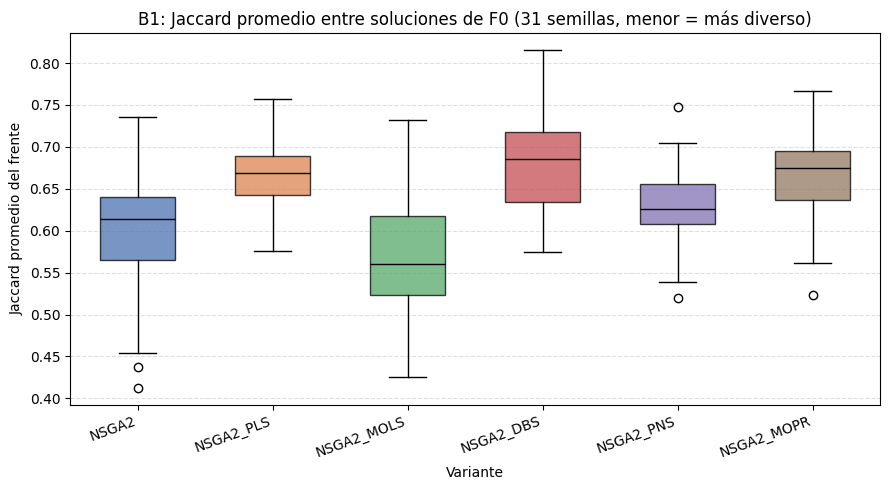

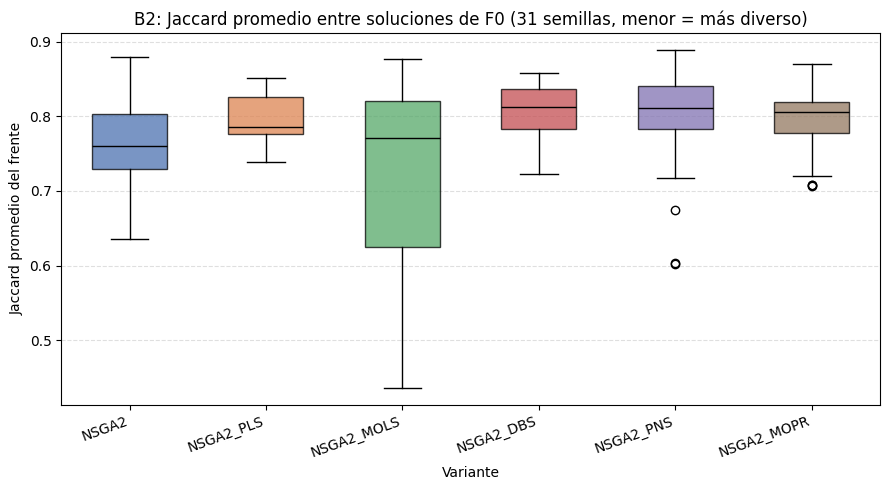

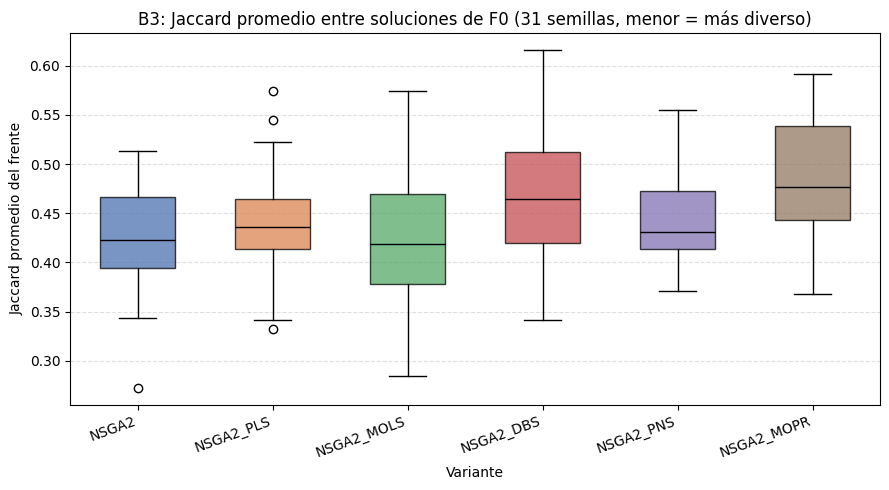

n   media    desv  minimo  mediana  maximo
dataset variante                                               
B1      NSGA2       31  0.5928  0.0790  0.4126   0.6145  0.7354
        NSGA2_DBS   31  0.6813  0.0558  0.5746   0.6856  0.8159
        NSGA2_MOLS  31  0.5685  0.0709  0.4252   0.5605  0.7322
        NSGA2_MOPR  31  0.6578  0.0535  0.5236   0.6752  0.7663
        NSGA2_PLS   31  0.6638  0.0398  0.5759   0.6683  0.7568
        NSGA2_PNS   31  0.6282  0.0499  0.5198   0.6258  0.7470
B2      NSGA2       31  0.7649  0.0580  0.6361   0.7599  0.8799
        NSGA2_DBS   31  0.8094  0.0363  0.7223   0.8125  0.8585
        NSGA2_MOLS  31  0.7192  0.1210  0.4365   0.7710  0.8770
        NSGA2_MOPR  31  0.7934  0.0445  0.7071   0.8056  0.8700
        NSGA2_PLS   31  0.7975  0.0320  0.7382   0.7859  0.8510
        NSGA2_PNS   31  0.7971  0.0702  0.6024   0.8114  0.8891
B3      NSGA2       31  0.4232  0.0544  0.2724   0.4229  0.5133
        NSGA2_DBS   31  0.4655  0.0665  0.3417   0.4643  0.6163
        NSGA2_MOLS  31  0.4242  0.0692  0.2848   0.4183  0.5741
        NSGA2_MOPR  31  0.4808  0.0633  0.3678   0.4769  0.5919
        NSGA2_PLS   31  0.4397  0.0545  0.3318   0.4357  0.5744
        NSGA2_PNS   31  0.4450  0.0461  0.3710   0.4312  0.5551

n  shapiro_w  p_valor normal (α=0.05)
dataset variante                                          
B1      NSGA2       31     0.9286   0.0401              no
        NSGA2_DBS   31     0.9867   0.9581              sí
        NSGA2_MOLS  31     0.9919   0.9970              sí
        NSGA2_MOPR  31     0.9390   0.0775              sí
        NSGA2_PLS   31     0.9742   0.6416              sí
        NSGA2_PNS   31     0.9781   0.7567              sí
B2      NSGA2       31     0.9849   0.9288              sí
        NSGA2_DBS   31     0.9352   0.0609              sí
        NSGA2_MOLS  31     0.9217   0.0262              no
        NSGA2_MOPR  31     0.9269   0.0362              no
        NSGA2_PLS   31     0.9470   0.1286              sí
        NSGA2_PNS   31     0.8662   0.0011              no
B3      NSGA2       31     0.9737   0.6268              sí
        NSGA2_DBS   31     0.9847   0.9247              sí
        NSGA2_MOLS  31     0.9846   0.9240              sí
        NSGA2_MOPR  31     0.9626   0.3407              sí
        NSGA2_PLS   31     0.9695   0.5045              sí
        NSGA2_PNS   31     0.9158   0.0183              no


[normalidad Jaccard] 5 de 18 conjuntos (dataset × variante) no superan Shapiro-Wilk con α=0.05.


In [8]:
#######################################################
# MODULO: ÍNDICE DE JACCARD ENTRE SOLUCIONES DEL FRENTE
#######################################################
# Por cada ejecución se reconstruyen los labels de clustering (vía GE) de las
# soluciones del F0 a partir de sus medoides, se calcula el índice de Jaccard
# por pares de soluciones y se promedia (excluye la diagonal). Es una medida de
# diversidad del frente en el espacio de las soluciones: MENOR Jaccard promedio
# = soluciones más distintas entre sí. Se repite el estudio de HV/IGD+/spread
# (boxplot por dataset + Shapiro-Wilk por dataset × variante).
# Requiere las matrices de distancia en Datasets/Matrices (<dataset>_S_DE.npz).
#######################################################

import matplotlib.pyplot as plt
from scipy import stats
from solution_encoding import build_clusters_population, load_distance_matrix
from performance import jaccard_index_solutions

MATRICES_DIR = THESIS_DIR / "Datasets" / "Matrices"

def jaccard_promedio_frente(ge_matrix: np.ndarray, medoids: np.ndarray) -> float:
    """Jaccard promedio entre pares de soluciones del frente (excluye diagonal)."""
    if len(medoids) < 2:
        return np.nan
    labels = build_clusters_population(ge_matrix, medoids)
    J = jaccard_index_solutions(labels)
    iu = np.triu_indices(len(medoids), k=1)
    return float(J[iu].mean())

historial = leer_historial()
if historial.empty:
    print("Aún no hay ejecuciones registradas.")
else:
    ultimas_jaccard = historial.sort_values("fecha").drop_duplicates(["variante", "dataset", "semilla"], keep="last")
    ORDEN_VARIANTES = list(VARIANTES)
    COLORES_VARIANTES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860"]
    indice_npz = {p.name: p for p in FRENTES_DIR.rglob("*.npz")}     # Tolera subcarpetas anidadas.

    filas_jaccard, faltantes_jaccard = [], []
    for nombre_ds, filas_ds in ultimas_jaccard.groupby("dataset"):
        archivo_ge = MATRICES_DIR / f"{nombre_ds}_S_DE.npz"
        if not archivo_ge.exists():
            print(f"[{nombre_ds}] aviso: falta {archivo_ge} (se omite el dataset).")
            continue
        ge_matrix, _ = load_distance_matrix(archivo_ge)              # Un dataset en memoria a la vez.
        for fila in filas_ds.itertuples():
            archivo = indice_npz.get(f"{fila.variante}_{nombre_ds}_{fila.semilla}.npz")
            if archivo is None:
                faltantes_jaccard.append(f"{fila.variante}_{nombre_ds}_{fila.semilla}.npz")
                continue
            with np.load(archivo) as datos:
                medoids = datos["medoids"]
            filas_jaccard.append({
                "dataset": nombre_ds, "variante": fila.variante, "semilla": fila.semilla,
                "tam_f0": len(medoids), "jaccard_promedio": jaccard_promedio_frente(ge_matrix, medoids),
            })
        del ge_matrix
    if faltantes_jaccard:
        print(f"[aviso] {len(faltantes_jaccard)} frentes .npz no encontrados en {FRENTES_DIR} (se omiten): "
              f"{faltantes_jaccard[:5]}{'...' if len(faltantes_jaccard) > 5 else ''}")

    jaccard_df = pd.DataFrame(filas_jaccard).dropna(subset=["jaccard_promedio"])
    jaccard_df.to_csv(RESULTS_DIR / "jaccard_ejecuciones.csv", index=False)
    datasets_jaccard = sorted(jaccard_df["dataset"].unique())

    for nombre_ds in datasets_jaccard:
        datos_ds = jaccard_df[jaccard_df["dataset"] == nombre_ds]
        grupos = [datos_ds.loc[datos_ds["variante"] == v, "jaccard_promedio"].to_numpy() for v in ORDEN_VARIANTES]
        tamanos = {v: len(g) for v, g in zip(ORDEN_VARIANTES, grupos)}
        if any(n != 31 for n in tamanos.values()):
            print(f"[{nombre_ds}] aviso: no todas las variantes tienen 31 ejecuciones -> {tamanos}")

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = ax.boxplot(grupos, tick_labels=ORDEN_VARIANTES, patch_artist=True, widths=0.55)
        for patch, color in zip(bp["boxes"], COLORES_VARIANTES):
            patch.set_facecolor(color)
            patch.set_alpha(0.75)
        for mediana in bp["medians"]:
            mediana.set_color("black")
        ax.set_title(f"{nombre_ds}: Jaccard promedio entre soluciones de F0 (31 semillas, menor = más diverso)")
        ax.set_xlabel("Variante")
        ax.set_ylabel("Jaccard promedio del frente")
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
        fig.tight_layout()
        plt.show()

    resumen_jaccard = (jaccard_df.groupby(["dataset", "variante"])["jaccard_promedio"]
                       .agg(n="size", media="mean", desv="std", minimo="min", mediana="median", maximo="max").round(4))
    resumen_jaccard.to_csv(RESULTS_DIR / "resumen_jaccard.csv")
    display(resumen_jaccard)

    filas_normalidad = []
    for (nombre_ds, variante), g in jaccard_df.groupby(["dataset", "variante"]):
        valores = g["jaccard_promedio"].to_numpy()
        estadistico, p_valor = stats.shapiro(valores)
        filas_normalidad.append({
            "dataset": nombre_ds, "variante": variante, "n": len(valores),
            "shapiro_w": round(float(estadistico), 4), "p_valor": round(float(p_valor), 4),
            "normal (α=0.05)": "sí" if p_valor > 0.05 else "no",
        })
    normalidad_jaccard = pd.DataFrame(filas_normalidad).sort_values(["dataset", "variante"]).set_index(["dataset", "variante"])
    normalidad_jaccard.to_csv(RESULTS_DIR / "normalidad_shapiro_jaccard.csv")
    sincronizar_drive()
    display(normalidad_jaccard)

    n_no_normales = (normalidad_jaccard["normal (α=0.05)"] == "no").sum()
    print(f"\n[normalidad Jaccard] {n_no_normales} de {len(normalidad_jaccard)} conjuntos (dataset × variante) "
          f"no superan Shapiro-Wilk con α=0.05.")


In [22]:
#######################################################
# PROTOTIPO: ÍNDICE DE WANG ENTRE SOLUCIONES DEL FRENTE (BioCluster)
#######################################################
# La matriz DB_M guarda similitud semántica de Wang gen–gen (load_distance_matrix
# la devuelve como distancia 1 − S, por eso aquí se invierte de nuevo).
# Para cada F0 (medoides -> labels vía GE -> lista de conjuntos de genes):
#   1) find_equivalent_clusters_jaccard: empareja los clusters equivalentes de
#      cada par de soluciones (BioCluster).
#   2) solution_go_similarity_from_dataframe: media de la similitud de Wang gen–gen
#      entre los clusters emparejados -> matriz solución × solución.
# Wang promedio del frente = media de los pares (sin diagonal). MAYOR = soluciones
# semánticamente más parecidas (MENOR = frente más diverso biológicamente).
# normalize_matrix=False: se conserva la escala real [0, 1] (si no, BioCluster
# divide por el máximo de cada matriz y no sería comparable entre frentes).
#######################################################

from solution_encoding import build_clusters_population, load_distance_matrix
from biocluster.clustering.jaccard_values import find_equivalent_clusters_jaccard
from biocluster.go.gene_similarity import solution_go_similarity_from_dataframe

MATRICES_DIR = THESIS_DIR / "Datasets" / "Matrices"

def cargar_ge_y_wang(nombre_ds: str) -> tuple:
    """GE (distancia), similitud de Wang gen–gen (1 − DB_M) y lista de genes de un dataset."""
    ge, genes = load_distance_matrix(MATRICES_DIR / f"{nombre_ds}_S_DE.npz")
    bi, genes_bi = load_distance_matrix(MATRICES_DIR / f"{nombre_ds}_S_DB_M.npz")
    assert genes == genes_bi, "GE y DB_M deben tener los mismos genes en el mismo orden."
    return ge, 1.0 - bi, genes

def wang_entre_soluciones(ge: np.ndarray, wang_genes: np.ndarray, genes: list, medoids: np.ndarray) -> np.ndarray:
    """Matriz (n_soluciones × n_soluciones) de similitud de Wang entre las soluciones de un frente."""
    labels = np.asarray(build_clusters_population(ge, medoids))                   # (n_sol, n_genes), 1-based
    soluciones = [[{genes[g] for g in np.flatnonzero(fila == k)} for k in range(1, int(fila.max()) + 1)
                   if (fila == k).any()] for fila in labels]                       # list[list[set[str]]]
    equivalentes = find_equivalent_clusters_jaccard(soluciones)
    matriz, _ = solution_go_similarity_from_dataframe(
        genes, wang_genes, "Wang", equivalentes, soluciones, normalize_matrix=False)
    return matriz

def wang_promedio_frente(ge, wang_genes, genes, medoids) -> float:
    if len(medoids) < 2:
        return np.nan
    W = wang_entre_soluciones(ge, wang_genes, genes, medoids)
    return float(W[np.triu_indices(len(W), k=1)].mean())

# --- Demostración: una ejecución por variante (primera semilla) en un dataset ---
DATASET_PROTOTIPO = "B1"
historial = leer_historial()
if historial.empty:
    print("Aún no hay ejecuciones registradas.")
else:
    ultimas_w = historial.sort_values("fecha").drop_duplicates(["variante", "dataset", "semilla"], keep="last")
    ultimas_w = ultimas_w[ultimas_w["dataset"] == DATASET_PROTOTIPO]
    indice_npz = {p.name: p for p in FRENTES_DIR.rglob("*.npz")}
    ge_p, wang_p, genes_p = cargar_ge_y_wang(DATASET_PROTOTIPO)

    filas = []
    for v in VARIANTES:
        g = ultimas_w[ultimas_w["variante"] == v]
        if g.empty:
            continue
        semilla = int(g["semilla"].iloc[0])
        archivo = indice_npz.get(f"{v}_{DATASET_PROTOTIPO}_{semilla}.npz")
        if archivo is None:
            continue
        with np.load(archivo) as d:
            medoids = d["medoids"]
        W = wang_entre_soluciones(ge_p, wang_p, genes_p, medoids)
        iu = np.triu_indices(len(W), k=1)
        filas.append({"variante": v, "semilla": semilla, "tam_f0": len(medoids),
                      "wang_promedio": round(float(W[iu].mean()), 4) if len(iu[0]) else np.nan,
                      "wang_min": round(float(W[iu].min()), 4) if len(iu[0]) else np.nan})
    display(pd.DataFrame(filas).set_index("variante"))


[load] 'B1_S_DE.npz' → matriz 3187×3187. Primer gen: 'CDH2', último: 'ENSG00000285973'.
[load] 'B1_S_DB_M.npz' → matriz 3187×3187. Primer gen: 'CDH2', último: 'ENSG00000285973'.


KeyboardInterrupt: 

In [23]:
#######################################################
# VERSIÓN RÁPIDA DEL WANG PROMEDIO DEL FRENTE (multiplicación de matrices)
#######################################################
# Reemplaza el cálculo de BioCluster (conjuntos de Python + iterrows + nanmean
# por submatriz) por multiplicaciones de matrices, en GPU si hay CuPy. El
# resultado coincide con BioCluster salvo redondeo float32 (~1e-5). Al final
# valida contra la versión original y redefine `wang_promedio_frente`, de modo que
# el módulo de boxplots de Wang use esta versión al ejecutarse después.
# Requiere haber ejecutado el prototipo (cargar_ge_y_wang, wang_entre_soluciones).
#######################################################

from solution_encoding import build_clusters_population

try:
    import cupy as cp                                       # Misma detección de GPU que solution_encoding.py.
    cp.zeros(1)
    _xp_w = cp
except Exception:
    _xp_w = np

_CACHE_S = {}                                               # Similitud gen–gen en el dispositivo (una por dataset).

def wang_promedio_frente_rapido(ge: np.ndarray, wang_genes: np.ndarray, genes: list, medoids: np.ndarray) -> float:
    """
    Wang promedio entre las soluciones de un frente, sin BioCluster ni conjuntos de genes:
      H (genes × clusters de todas las soluciones) indicadora de pertenencia.
      inter = Hᵀ H            -> |A∩B| de todos los pares de clusters (Jaccard + emparejamiento voraz).
      sumas = Hᵀ S H          -> suma de similitud gen–gen entre todos los pares de clusters.
    La similitud entre dos clusters emparejados es sumas[a, b] / (|A||B|), igual que nanmean(S[A, B]).
    """
    if len(medoids) < 2:
        return np.nan
    xp = _xp_w
    clave = id(wang_genes)
    if clave not in _CACHE_S:
        _CACHE_S.clear()                                    # Un dataset en el dispositivo a la vez.
        S = np.asarray(wang_genes, dtype=np.float32)
        validos = np.isfinite(S)
        _CACHE_S[clave] = (xp.asarray(np.where(validos, S, 0.0)),
                           None if validos.all() else xp.asarray(validos.astype(np.float32)))
    S_d, validos_d = _CACHE_S[clave]

    labels = np.asarray(build_clusters_population(ge, medoids))
    labels = labels.get() if hasattr(labels, "get") else labels                  # (n_sol, n_genes), 1-based
    n_sol, n_genes = labels.shape
    columnas, offsets = [], [0]
    for fila in labels:
        etiquetas = np.unique(fila)                                              # Solo clusters no vacíos, en orden de etiqueta.
        columnas.append(fila[None, :] == etiquetas[:, None])                     # (K_i, n_genes)
        offsets.append(offsets[-1] + len(etiquetas))
    H = xp.asarray(np.vstack(columnas).T.astype(np.float32))                     # (n_genes, T)

    tamanos = H.sum(axis=0)
    inter = H.T @ H
    sumas = H.T @ (S_d @ H)
    if validos_d is None:
        cuenta = tamanos[:, None] * tamanos[None, :]
    else:                                                                        # nanmean: solo pares de genes con valor.
        cuenta = H.T @ (validos_d @ H)
    tamanos, inter, sumas, cuenta = (a.get() if hasattr(a, "get") else a for a in (tamanos, inter, sumas, cuenta))

    medias_pares = []
    for i in range(n_sol):
        a0, a1 = offsets[i], offsets[i + 1]
        for j in range(i + 1, n_sol):
            b0, b1 = offsets[j], offsets[j + 1]
            union = tamanos[a0:a1, None] + tamanos[None, b0:b1] - inter[a0:a1, b0:b1]
            M = np.divide(inter[a0:a1, b0:b1], union, out=np.zeros_like(union, dtype=float), where=union > 0)
            n1, n2 = M.shape
            usados1, usados2, sims = set(), set(), []
            for idx in np.argsort(M.ravel())[::-1]:                              # Emparejamiento voraz (igual que BioCluster).
                p, q = idx // n2, idx % n2
                if p not in usados1 and q not in usados2:
                    c = cuenta[a0 + p, b0 + q]
                    sims.append(sumas[a0 + p, b0 + q] / c if c > 0 else 0.0)
                    usados1.add(p); usados2.add(q)
                if len(usados1) == n1 or len(usados2) == n2:
                    break
            medias_pares.append(np.mean(sims))
    return float(np.mean(medias_pares))

############################
# Validación contra BioCluster y reemplazo
############################
if "wang_promedio_frente_biocluster" not in globals():
    wang_promedio_frente_biocluster = wang_promedio_frente          # Se conserva la versión original.

N_VALIDACION = 3                                                    # Frentes comparados por dataset.
DATASET_VALIDACION = "B1"
historial = leer_historial()
indice_npz = {p.name: p for p in FRENTES_DIR.rglob("*.npz")}
muestra = [(f.variante, f.semilla) for f in historial[historial["dataset"] == DATASET_VALIDACION]
           .drop_duplicates(["variante", "semilla"]).itertuples()
           if f"{f.variante}_{DATASET_VALIDACION}_{f.semilla}.npz" in indice_npz][:N_VALIDACION]
if not muestra:
    print("Sin frentes para validar.")
else:
    import time
    ge_v, wang_v, genes_v = cargar_ge_y_wang(DATASET_VALIDACION)
    filas = []
    for variante, semilla in muestra:
        with np.load(indice_npz[f"{variante}_{DATASET_VALIDACION}_{semilla}.npz"]) as d:
            medoids = d["medoids"]
        t0 = time.time(); w_bio = wang_promedio_frente_biocluster(ge_v, wang_v, genes_v, medoids); t_bio = time.time() - t0
        t0 = time.time(); w_rap = wang_promedio_frente_rapido(ge_v, wang_v, genes_v, medoids);     t_rap = time.time() - t0
        filas.append({"variante": variante, "semilla": semilla, "tam_f0": len(medoids),
                      "wang_biocluster": w_bio, "wang_rapido": w_rap, "|dif|": abs(w_bio - w_rap),
                      "s_biocluster": round(t_bio, 2), "s_rapido": round(t_rap, 2)})
    display(pd.DataFrame(filas).set_index("variante"))
    assert max(f["|dif|"] for f in filas) < 1e-3, "La versión rápida no coincide con BioCluster."

    wang_promedio_frente = wang_promedio_frente_rapido              # El módulo de boxplots usa esta versión.
    print("[wang] `wang_promedio_frente` ahora usa la versión rápida.")


[load] 'B1_S_DE.npz' → matriz 3187×3187. Primer gen: 'CDH2', último: 'ENSG00000285973'.
[load] 'B1_S_DB_M.npz' → matriz 3187×3187. Primer gen: 'CDH2', último: 'ENSG00000285973'.


,semilla,tam_f0,wang_biocluster,wang_rapido,|dif|,s_biocluster,s_rapido
variante,,,,,,,
NSGA2,1183181808,9,0.137540,0.137533,0.000007,1.48,0.03
NSGA2,1270388439,9,0.132872,0.132857,0.000015,1.50,0.01
NSGA2,1658144228,8,0.136424,0.136417,0.000007,1.19,0.01


[wang] `wang_promedio_frente` ahora usa la versión rápida.


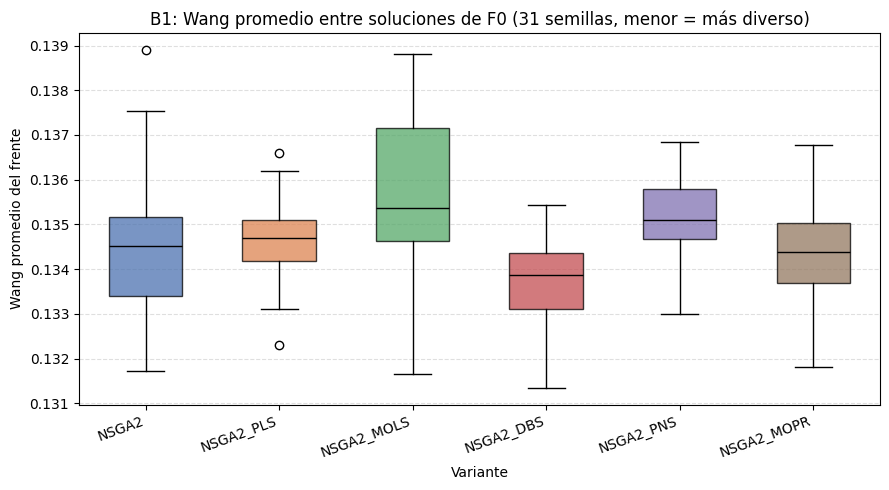

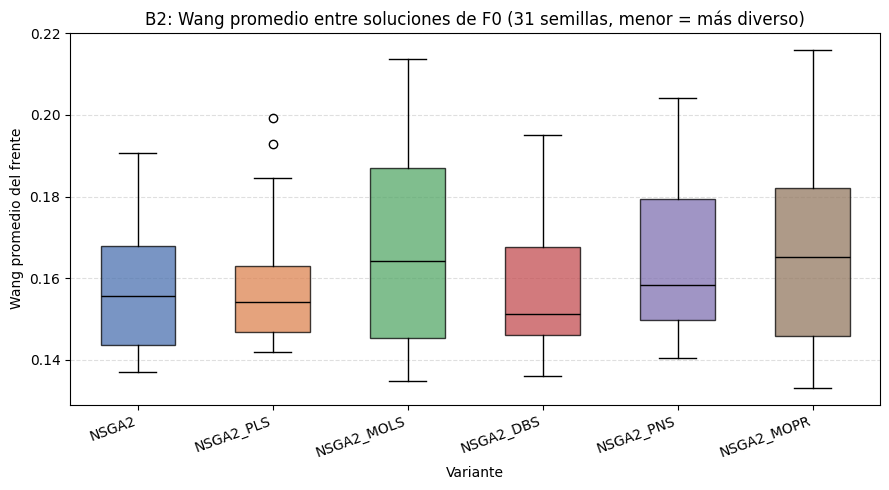

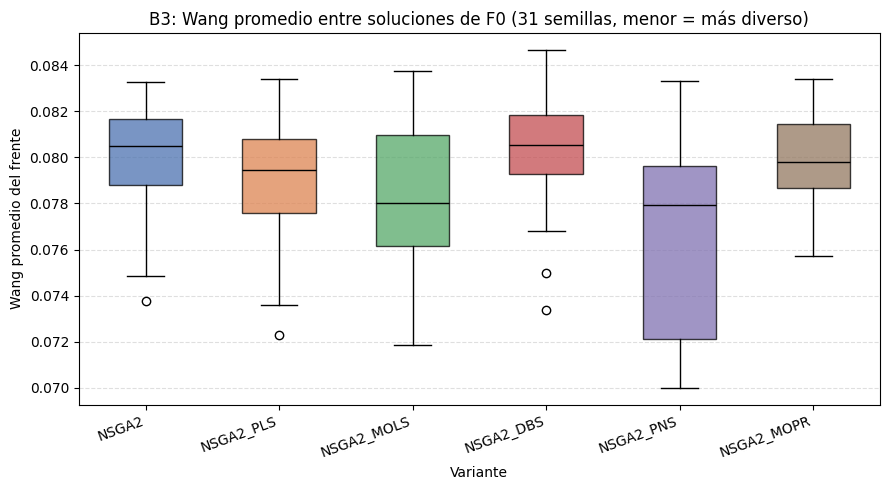

n   media    desv  minimo  mediana  maximo
dataset variante                                               
B1      NSGA2       31  0.1345  0.0016  0.1317   0.1345  0.1389
        NSGA2_DBS   31  0.1338  0.0010  0.1313   0.1339  0.1354
        NSGA2_MOLS  31  0.1357  0.0017  0.1317   0.1354  0.1388
        NSGA2_MOPR  31  0.1343  0.0013  0.1318   0.1344  0.1368
        NSGA2_PLS   31  0.1346  0.0010  0.1323   0.1347  0.1366
        NSGA2_PNS   31  0.1352  0.0010  0.1330   0.1351  0.1368
B2      NSGA2       31  0.1572  0.0150  0.1369   0.1556  0.1907
        NSGA2_DBS   31  0.1569  0.0155  0.1361   0.1513  0.1950
        NSGA2_MOLS  31  0.1662  0.0241  0.1349   0.1642  0.2137
        NSGA2_MOPR  31  0.1661  0.0217  0.1332   0.1651  0.2160
        NSGA2_PLS   31  0.1584  0.0153  0.1420   0.1541  0.1993
        NSGA2_PNS   31  0.1661  0.0201  0.1404   0.1583  0.2041
B3      NSGA2       31  0.0800  0.0023  0.0738   0.0805  0.0833
        NSGA2_DBS   31  0.0803  0.0024  0.0734   0.0806  0.0847
        NSGA2_MOLS  31  0.0782  0.0031  0.0718   0.0780  0.0837
        NSGA2_MOPR  31  0.0798  0.0020  0.0757   0.0798  0.0834
        NSGA2_PLS   31  0.0790  0.0028  0.0723   0.0794  0.0834
        NSGA2_PNS   31  0.0767  0.0040  0.0700   0.0779  0.0833

n  shapiro_w  p_valor normal (α=0.05)
dataset variante                                          
B1      NSGA2       31     0.9680   0.4657              sí
        NSGA2_DBS   31     0.9707   0.5374              sí
        NSGA2_MOLS  31     0.9667   0.4337              sí
        NSGA2_MOPR  31     0.9774   0.7374              sí
        NSGA2_PLS   31     0.9834   0.8997              sí
        NSGA2_PNS   31     0.9657   0.4085              sí
B2      NSGA2       31     0.9445   0.1103              sí
        NSGA2_DBS   31     0.9255   0.0331              no
        NSGA2_MOLS  31     0.9110   0.0137              no
        NSGA2_MOPR  31     0.9591   0.2757              sí
        NSGA2_PLS   31     0.8322   0.0002              no
        NSGA2_PNS   31     0.9103   0.0132              no
B3      NSGA2       31     0.9316   0.0485              no
        NSGA2_DBS   31     0.9535   0.1945              sí
        NSGA2_MOLS  31     0.9730   0.6062              sí
        NSGA2_MOPR  31     0.9746   0.6521              sí
        NSGA2_PLS   31     0.9529   0.1879              sí
        NSGA2_PNS   31     0.9086   0.0119              no


[normalidad Wang] 6 de 18 conjuntos (dataset × variante) no superan Shapiro-Wilk con α=0.05.


In [18]:
#######################################################
# MODULO: ÍNDICE DE WANG PROMEDIO ENTRE SOLUCIONES DEL FRENTE
#######################################################
# Misma dinámica que el módulo de Jaccard: por cada ejecución se calcula el Wang
# promedio entre las soluciones de su F0 (ver el prototipo anterior), y se
# presenta boxplot por dataset + Shapiro-Wilk por dataset × variante.
# MAYOR Wang = soluciones semánticamente más parecidas (MENOR = más diverso).
# El cálculo es lento: los valores ya calculados se guardan en
# wang_ejecuciones.csv y se reutilizan (la celda se puede interrumpir y reanudar).
# Requiere haber ejecutado el prototipo (define wang_promedio_frente y cargar_ge_y_wang).
#######################################################

import matplotlib.pyplot as plt
from scipy import stats

if "wang_promedio_frente" not in globals():
    print("Primero ejecuta el prototipo de Wang (define `wang_promedio_frente` y `cargar_ge_y_wang`).")
else:
    WANG_FILE = RESULTS_DIR / "wang_ejecuciones.csv"
    DATASETS_WANG = None                 # None = todos los del historial; p. ej. ["B1"] para una prueba.
    ORDEN_VARIANTES = list(VARIANTES)
    COLORES_VARIANTES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860"]

    historial = leer_historial()
    ultimas_wang = historial.sort_values("fecha").drop_duplicates(["variante", "dataset", "semilla"], keep="last")
    if DATASETS_WANG is not None:
        ultimas_wang = ultimas_wang[ultimas_wang["dataset"].isin(DATASETS_WANG)]

    previas = pd.read_csv(WANG_FILE) if WANG_FILE.exists() else pd.DataFrame(
        columns=["dataset", "variante", "semilla", "tam_f0", "wang_promedio"])
    hechas = set(zip(previas["variante"], previas["dataset"], previas["semilla"]))
    indice_npz = {p.name: p for p in FRENTES_DIR.rglob("*.npz")}     # Tolera subcarpetas anidadas.

    nuevas, faltantes_wang = [], []
    for nombre_ds, filas_ds in ultimas_wang.groupby("dataset"):
        pendientes = [f for f in filas_ds.itertuples() if (f.variante, nombre_ds, f.semilla) not in hechas]
        if not pendientes:
            continue
        try:
            ge_w, wang_w, genes_w = cargar_ge_y_wang(nombre_ds)       # Un dataset en memoria a la vez.
        except FileNotFoundError as e:
            print(f"[{nombre_ds}] aviso: {e} (se omite el dataset).")
            continue
        for i, fila in enumerate(pendientes, 1):
            archivo = indice_npz.get(f"{fila.variante}_{nombre_ds}_{fila.semilla}.npz")
            if archivo is None:
                faltantes_wang.append(f"{fila.variante}_{nombre_ds}_{fila.semilla}.npz")
                continue
            with np.load(archivo) as datos:
                medoids = datos["medoids"]
            nuevas.append({"dataset": nombre_ds, "variante": fila.variante, "semilla": fila.semilla,
                           "tam_f0": len(medoids),
                           "wang_promedio": wang_promedio_frente(ge_w, wang_w, genes_w, medoids)})
            if i % 20 == 0:
                print(f"[{nombre_ds}] {i}/{len(pendientes)} frentes procesados")
        del ge_w, wang_w
    if faltantes_wang:
        print(f"[aviso] {len(faltantes_wang)} frentes .npz no encontrados en {FRENTES_DIR} (se omiten): {faltantes_wang[:5]} ...")

    wang_df = pd.concat([previas, pd.DataFrame(nuevas)], ignore_index=True) if nuevas else previas
    wang_df.to_csv(WANG_FILE, index=False)
    sincronizar_drive()
    llaves = set(zip(ultimas_wang["variante"], ultimas_wang["dataset"], ultimas_wang["semilla"]))
    wang_df = wang_df[[(v, d, s) in llaves for v, d, s in
                       zip(wang_df["variante"], wang_df["dataset"], wang_df["semilla"])]].dropna(subset=["wang_promedio"])
    datasets_wang = sorted(wang_df["dataset"].unique())

    for nombre_ds in datasets_wang:
        datos_ds = wang_df[wang_df["dataset"] == nombre_ds]
        grupos = [datos_ds.loc[datos_ds["variante"] == v, "wang_promedio"].to_numpy() for v in ORDEN_VARIANTES]
        tamanos = {v: len(g) for v, g in zip(ORDEN_VARIANTES, grupos)}
        if any(n != 31 for n in tamanos.values()):
            print(f"[{nombre_ds}] aviso: no todas las variantes tienen 31 ejecuciones -> {tamanos}")

        fig, ax = plt.subplots(figsize=(9, 5))
        bp = ax.boxplot(grupos, tick_labels=ORDEN_VARIANTES, patch_artist=True, widths=0.55)
        for patch, color in zip(bp["boxes"], COLORES_VARIANTES):
            patch.set_facecolor(color)
            patch.set_alpha(0.75)
        for mediana in bp["medians"]:
            mediana.set_color("black")
        ax.set_title(f"{nombre_ds}: Wang promedio entre soluciones de F0 (31 semillas, menor = más diverso)")
        ax.set_xlabel("Variante")
        ax.set_ylabel("Wang promedio del frente")
        ax.grid(axis="y", linestyle="--", alpha=0.4)
        plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
        fig.tight_layout()
        plt.show()

    resumen_wang = (wang_df.groupby(["dataset", "variante"])["wang_promedio"]
                    .agg(n="size", media="mean", desv="std", minimo="min", mediana="median", maximo="max").round(4))
    resumen_wang.to_csv(RESULTS_DIR / "resumen_wang.csv")
    display(resumen_wang)

    filas_normalidad = []
    for (nombre_ds, variante), g in wang_df.groupby(["dataset", "variante"]):
        valores = g["wang_promedio"].to_numpy()
        estadistico, p_valor = stats.shapiro(valores)
        filas_normalidad.append({
            "dataset": nombre_ds, "variante": variante, "n": len(valores),
            "shapiro_w": round(float(estadistico), 4), "p_valor": round(float(p_valor), 4),
            "normal (α=0.05)": "sí" if p_valor > 0.05 else "no",
        })
    normalidad_wang = pd.DataFrame(filas_normalidad).sort_values(["dataset", "variante"]).set_index(["dataset", "variante"])
    normalidad_wang.to_csv(RESULTS_DIR / "normalidad_shapiro_wang.csv")
    sincronizar_drive()
    display(normalidad_wang)

    n_no_normales = (normalidad_wang["normal (α=0.05)"] == "no").sum()
    print(f"\n[normalidad Wang] {n_no_normales} de {len(normalidad_wang)} conjuntos (dataset × variante) no superan Shapiro-Wilk con α=0.05.")


[backend] CuPy detectado → operaciones vectorizadas en GPU.
[load] 'B1_S_DE.npz' → matriz 3187×3187. Primer gen: 'CDH2', último: 'ENSG00000285973'.
[B1] 2933/3187 genes con Entrez
[B1] 0 clusters nuevos por consultar (22712 ya en caché)
[load] 'B2_S_DE.npz' → matriz 3024×3024. Primer gen: 'A1BG', último: 'ENSG00000284779'.
[B2] 2843/3024 genes con Entrez
[B2] 0 clusters nuevos por consultar (22712 ya en caché)
[load] 'B3_S_DE.npz' → matriz 10616×10616. Primer gen: 'CDH2', último: 'ENSG00000285994'.
[B3] 8326/10616 genes con Entrez
[B3] 13881 clusters nuevos por consultar (22712 ya en caché)
[B3] 50/13881 consultados
[B3] 100/13881 consultados
[B3] 150/13881 consultados
[B3] 200/13881 consultados
[B3] 250/13881 consultados
[B3] 300/13881 consultados
[B3] 350/13881 consultados
[B3] 400/13881 consultados
[B3] 450/13881 consultados
[B3] 500/13881 consultados
[B3] 550/13881 consultados
[B3] 600/13881 consultados
[B3] 650/13881 consultados
[B3] 700/13881 consultados
[B3] 750/13881 consultado

C:\Users\benja\AppData\Local\Temp\ipykernel_20400\14534508.py:132: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  david_df = pd.concat([previas, pd.DataFrame(nuevas)], ignore_index=True) if nuevas else previas


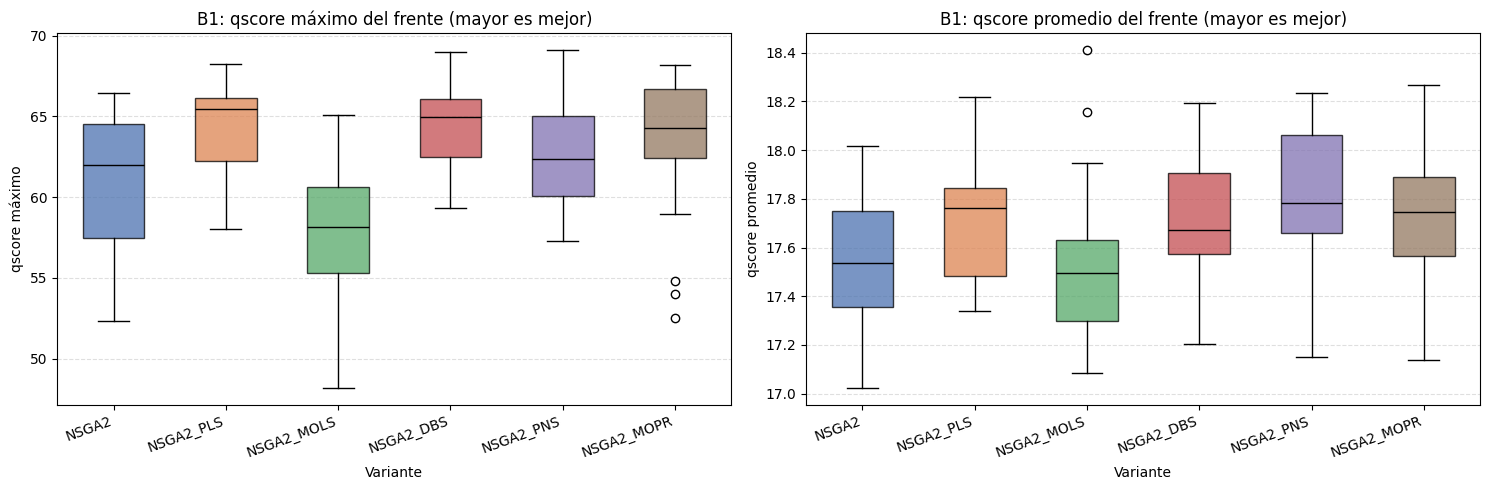

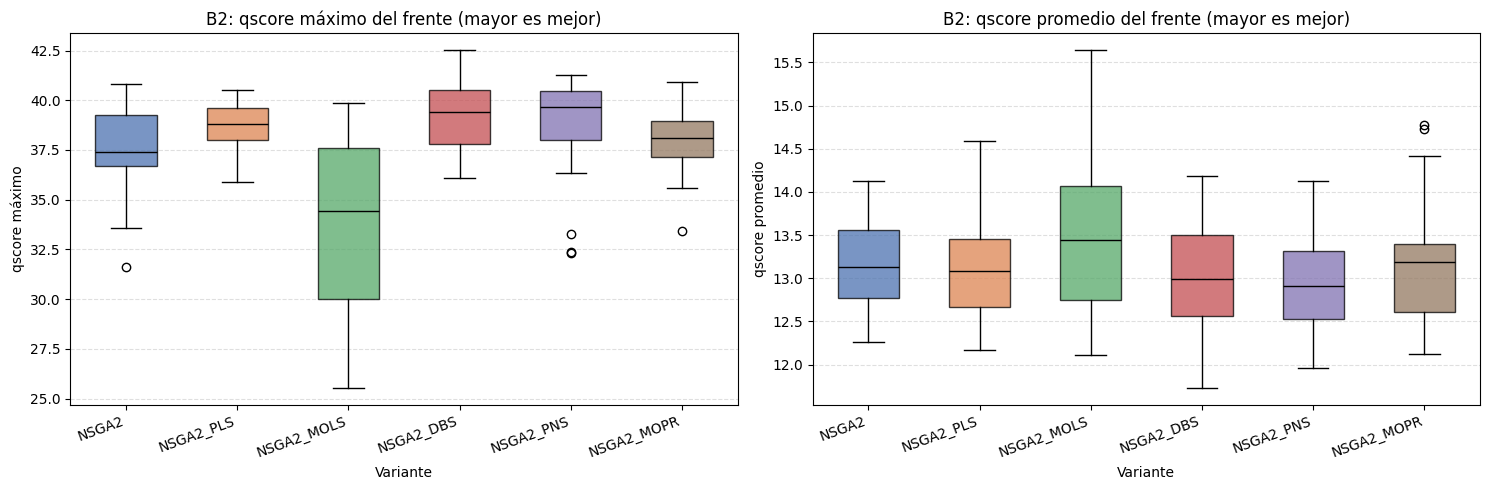

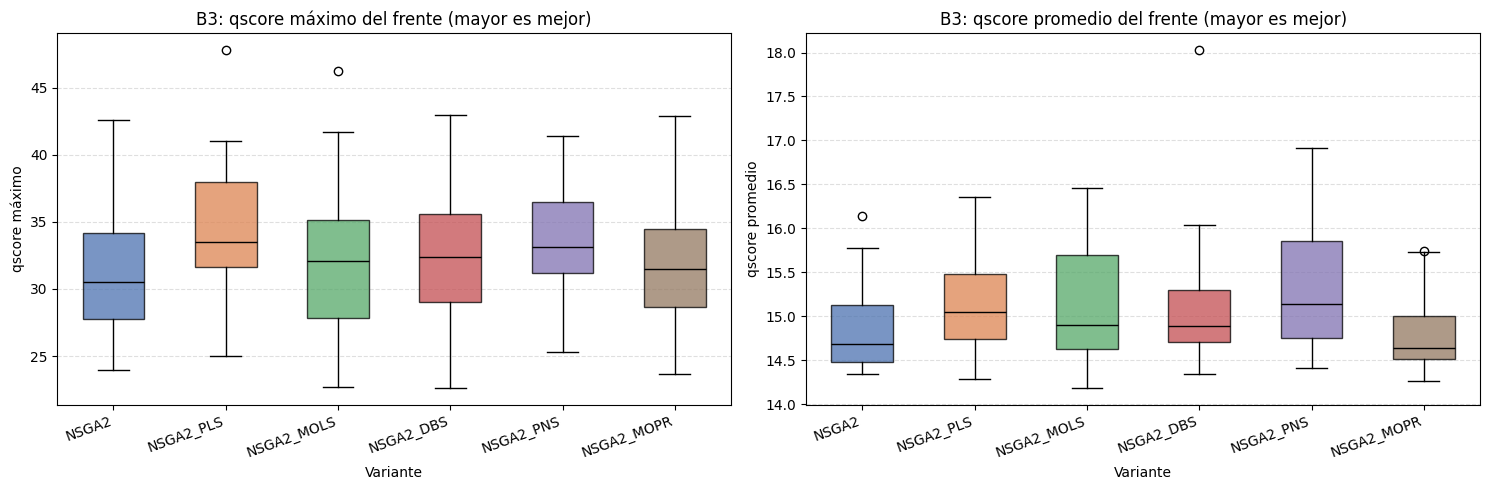

qscore_max                                    qscore_prom  \
                         mean     std      min   median      max        mean   
dataset variante                                                               
B1      NSGA2         61.0271  4.0042  52.3211  61.9707  66.4245     17.5511   
        NSGA2_DBS     64.3699  2.5134  59.3373  64.9377  68.9700     17.7262   
        NSGA2_MOLS    58.0176  4.0294  48.1901  58.1366  65.0609     17.5093   
        NSGA2_MOPR    63.4665  4.0011  52.5138  64.2631  68.1578     17.7272   
        NSGA2_PLS     64.3921  2.7362  58.0199  65.4566  68.2332     17.7227   
        NSGA2_PNS     62.6219  3.1177  57.2811  62.3532  69.1253     17.8186   
B2      NSGA2         37.5098  2.0333  31.6321  37.3921  40.8427     13.1097   
        NSGA2_DBS     39.3254  1.7196  36.0762  39.3990  42.5410     12.9668   
        NSGA2_MOLS    33.7193  4.3345  25.5385  34.4278  39.8495     13.5212   
        NSGA2_MOPR    38.0956  1.6996  33.4336  38.0790  40.9357     13.1234   
        NSGA2_PLS     38.7735  1.1613  35.8953  38.8159  40.5246     13.1391   
        NSGA2_PNS     38.7930  2.4469  32.3071  39.6775  41.2626     12.8815   
B3      NSGA2         31.2840  4.8996  23.9839  30.5400  42.5969     14.8424   
        NSGA2_DBS     32.5597  4.9029  22.6288  32.3550  42.9420     15.0844   
        NSGA2_MOLS    32.0445  5.4497  22.6645  32.0853  46.2696     15.0889   
        NSGA2_MOPR    32.0527  4.3529  23.6502  31.4757  42.8936     14.7919   
        NSGA2_PLS     34.3564  4.8720  25.0133  33.4679  47.8250     15.1425   
        NSGA2_PNS     33.7739  3.5892  25.3325  33.1423  41.3962     15.3393   

                                                       
                       std      min   median      max  
dataset variante                                       
B1      NSGA2       0.2715  17.0235  17.5365  18.0170  
        NSGA2_DBS   0.2350  17.2038  17.6734  18.1931  
        NSGA2_MOLS  0.3010  17.0852  17.4942  18.4127  
        NSGA2_MOPR  0.2789  17.1364  17.7461  18.2684  
        NSGA2_PLS   0.2608  17.3389  17.7627  18.2195  
        NSGA2_PNS   0.2759  17.1510  17.7809  18.2335  
B2      NSGA2       0.5052  12.2568  13.1271  14.1255  
        NSGA2_DBS   0.6833  11.7312  12.9935  14.1868  
        NSGA2_MOLS  0.9397  12.1167  13.4423  15.6470  
        NSGA2_MOPR  0.6734  12.1174  13.1884  14.7708  
        NSGA2_PLS   0.6242  12.1667  13.0795  14.5861  
        NSGA2_PNS   0.5823  11.9623  12.9103  14.1214  
B3      NSGA2       0.4692  14.3472  14.6834  16.1378  
        NSGA2_DBS   0.7015  14.3469  14.8835  18.0318  
        NSGA2_MOLS  0.6257  14.1849  14.8991  16.4557  
        NSGA2_MOPR  0.4098  14.2640  14.6418  15.7415  
        NSGA2_PLS   0.4998  14.2881  15.0424  16.3528  
        NSGA2_PNS   0.7481  14.4116  15.1367  16.9118

n  shapiro_w  p_valor normal (α=0.05)
dataset metrica     variante                                          
B1      qscore_max  NSGA2       31     0.9344   0.0579              sí
                    NSGA2_DBS   31     0.9650   0.3935              sí
                    NSGA2_MOLS  31     0.9812   0.8442              sí
                    NSGA2_MOPR  31     0.8632   0.0010              no
                    NSGA2_PLS   31     0.9183   0.0212              no
                    NSGA2_PNS   31     0.9675   0.4537              sí
        qscore_prom NSGA2       31     0.9707   0.5378              sí
                    NSGA2_DBS   31     0.9841   0.9142              sí
                    NSGA2_MOLS  31     0.9293   0.0420              no
                    NSGA2_MOPR  31     0.9845   0.9221              sí
                    NSGA2_PLS   31     0.9448   0.1123              sí
                    NSGA2_PNS   31     0.9422   0.0947              sí
B2      qscore_max  NSGA2       31     0.9430   0.0999              sí
                    NSGA2_DBS   31     0.9723   0.5855              sí
                    NSGA2_MOLS  31     0.9288   0.0406              no
                    NSGA2_MOPR  31     0.9594   0.2814              sí
                    NSGA2_PLS   31     0.9693   0.4990              sí
                    NSGA2_PNS   31     0.8121   0.0001              no
        qscore_prom NSGA2       31     0.9678   0.4616              sí
                    NSGA2_DBS   31     0.9747   0.6563              sí
                    NSGA2_MOLS  31     0.9609   0.3090              sí
                    NSGA2_MOPR  31     0.9267   0.0357              no
                    NSGA2_PLS   31     0.9707   0.5387              sí
                    NSGA2_PNS   31     0.9709   0.5453              sí
B3      qscore_max  NSGA2       31     0.9507   0.1635              sí
                    NSGA2_DBS   31     0.9868   0.9602              sí
                    NSGA2_MOLS  31     0.9716   0.5647              sí
                    NSGA2_MOPR  31     0.9722   0.5801              sí
                    NSGA2_PLS   31     0.9764   0.7086              sí
                    NSGA2_PNS   31     0.9776   0.7430              sí
        qscore_prom NSGA2       31     0.8822   0.0027              no
                    NSGA2_DBS   31     0.7613   0.0000              no
                    NSGA2_MOLS  31     0.9264   0.0349              no
                    NSGA2_MOPR  31     0.8822   0.0027              no
                    NSGA2_PLS   31     0.9626   0.3404              sí
                    NSGA2_PNS   31     0.8965   0.0059              no


[normalidad DAVID] 11 de 36 conjuntos (dataset × variante × métrica) no superan Shapiro-Wilk con α=0.05.


In [3]:
#######################################################
# MODULO: ENRIQUECIMIENTO TIPO DAVID (qscore de BioCluster)
#######################################################
# qscore = -log10(p) * gene_ratio de cada término GO:BP significativo (g:Profiler,
# BioCluster.go_enrichment). Se toma como equivalente del "enrichment" de DAVID:
#   - Por cada cluster de cada solución del F0: qscore del cluster = mayor qscore
#     de sus términos (0 si no hay términos significativos).
#   - Por solución: qscore MÁXIMO = máximo entre sus clusters; qscore PROMEDIO =
#     media entre sus clusters.
#   - Por frente (una ejecución): media de esos dos valores entre las soluciones
#     del F0. MAYOR es mejor (más enriquecimiento biológico).
# Los genes se traducen a Entrez con Datasets/trazabilidad_genes.csv (los genes
# sin Entrez, p. ej. ENSG conservados, se excluyen de la consulta).
# REQUIERE INTERNET (g:Profiler). Cada cluster distinto se consulta una sola vez:
# el resultado se guarda en david_cache_clusters.json y los valores por ejecución
# en david_ejecuciones.csv, por lo que la celda se puede interrumpir y reanudar.
#######################################################

import json
import hashlib
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from scipy import stats
from biocluster.go.go_enrichment import go_enrichment, GoEnrichmentOptions
from solution_encoding import build_clusters_population, load_distance_matrix

DATASETS_DAVID  = None          # None = todos los del historial; p. ej. ["B1"] para una prueba.
MAX_WORKERS     = 6             # Consultas simultáneas a g:Profiler.
MIN_GENES       = 2             # Un cluster con menos genes con Entrez no se consulta (qscore = 0).
OPCIONES_GO     = GoEnrichmentOptions(sources=("GO:BP",), user_threshold=0.05)

MATRICES_DIR    = THESIS_DIR / "Datasets" / "Matrices"
TRAZABILIDAD    = THESIS_DIR / "Datasets" / "trazabilidad_genes.csv"
CACHE_FILE      = RESULTS_DIR / "david_cache_clusters.json"
DAVID_FILE      = RESULTS_DIR / "david_ejecuciones.csv"

def entrez_por_gen(nombre_ds: str, genes: list) -> list:
    """Entrez ID de cada gen de la matriz (None si no tiene), según trazabilidad_genes.csv."""
    t = pd.read_csv(TRAZABILIDAD, dtype=str)
    t = t[t["dataset"] == nombre_ds].dropna(subset=["symbol_final", "entrez_id_mapeado"])
    mapa = t.drop_duplicates("symbol_final").set_index("symbol_final")["entrez_id_mapeado"].to_dict()
    return [mapa.get(g) for g in genes]

def llave_cluster(ids: list) -> str:
    return hashlib.sha1(",".join(sorted(ids)).encode()).hexdigest()

def consultar_cluster(ids: list) -> dict:
    """qscore máximo y medio de los términos GO:BP significativos de un cluster."""
    if len(ids) < MIN_GENES:
        return {"q_max": 0.0, "q_medio": 0.0, "n_terminos": 0}
    df = go_enrichment(ids, OPCIONES_GO)
    if df.empty:
        return {"q_max": 0.0, "q_medio": 0.0, "n_terminos": 0}
    return {"q_max": float(df["qscore"].max()), "q_medio": float(df["qscore"].mean()), "n_terminos": int(len(df))}

if "FRENTES_DIR" not in globals():
    print("Primero ejecuta la celda de preparación del ambiente.")
else:
    ORDEN_VARIANTES = list(VARIANTES)
    COLORES_VARIANTES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2", "#937860"]

    historial = leer_historial()
    ultimas_dv = historial.sort_values("fecha").drop_duplicates(["variante", "dataset", "semilla"], keep="last")
    if DATASETS_DAVID is not None:
        ultimas_dv = ultimas_dv[ultimas_dv["dataset"].isin(DATASETS_DAVID)]

    cache = json.loads(CACHE_FILE.read_text(encoding="utf-8")) if CACHE_FILE.exists() else {}
    previas = pd.read_csv(DAVID_FILE) if DAVID_FILE.exists() else pd.DataFrame(
        columns=["dataset", "variante", "semilla", "tam_f0", "qscore_max", "qscore_prom"])
    hechas = set(zip(previas["variante"], previas["dataset"], previas["semilla"]))
    indice_npz = {p.name: p for p in FRENTES_DIR.rglob("*.npz")}

    nuevas, faltantes_dv = [], []
    for nombre_ds, filas_ds in ultimas_dv.groupby("dataset"):
        pendientes = [f for f in filas_ds.itertuples() if (f.variante, nombre_ds, f.semilla) not in hechas
                      and f"{f.variante}_{nombre_ds}_{f.semilla}.npz" in indice_npz]
        faltantes_dv += [f"{f.variante}_{nombre_ds}_{f.semilla}.npz" for f in filas_ds.itertuples()
                         if f"{f.variante}_{nombre_ds}_{f.semilla}.npz" not in indice_npz]
        if not pendientes:
            continue
        archivo_ge = MATRICES_DIR / f"{nombre_ds}_S_DE.npz"
        if not archivo_ge.exists():
            print(f"[{nombre_ds}] aviso: falta {archivo_ge} (se omite el dataset).")
            continue
        ge_d, genes_d = load_distance_matrix(archivo_ge)
        entrez = np.array(entrez_por_gen(nombre_ds, genes_d), dtype=object)
        print(f"[{nombre_ds}] {sum(e is not None for e in entrez)}/{len(entrez)} genes con Entrez")

        # 1) Clusters (como listas de Entrez) de cada solución de cada frente pendiente.
        estructura = {}                                   # (variante, semilla) -> [[llave de cada cluster] por solución]
        por_consultar = {}                                # llave -> ids
        for fila in pendientes:
            with np.load(indice_npz[f"{fila.variante}_{nombre_ds}_{fila.semilla}.npz"]) as d:
                medoids = d["medoids"]
            labels = np.asarray(build_clusters_population(ge_d, medoids))
            labels = labels.get() if hasattr(labels, "get") else labels
            soluciones = []
            for fila_labels in labels:
                llaves = []
                for k in np.unique(fila_labels):
                    ids = [e for e in entrez[fila_labels == k] if e is not None]
                    llave = llave_cluster(ids)
                    llaves.append(llave)
                    if llave not in cache:
                        por_consultar[llave] = ids
                soluciones.append(llaves)
            estructura[(fila.variante, fila.semilla)] = soluciones

        # 2) Consultas a g:Profiler solo de los clusters nuevos (en paralelo, con guardado periódico).
        print(f"[{nombre_ds}] {len(por_consultar)} clusters nuevos por consultar "
              f"({len(cache)} ya en caché)")
        llaves_pend = list(por_consultar)
        for inicio in range(0, len(llaves_pend), 50):
            lote = llaves_pend[inicio:inicio + 50]
            with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
                for llave, res in zip(lote, pool.map(lambda l: consultar_cluster(por_consultar[l]), lote)):
                    cache[llave] = res
            CACHE_FILE.write_text(json.dumps(cache), encoding="utf-8")
            print(f"[{nombre_ds}] {min(inicio + 50, len(llaves_pend))}/{len(llaves_pend)} consultados")

        # 3) Métricas por frente.
        for (variante, semilla), soluciones in estructura.items():
            q_max_sol = [max(cache[l]["q_max"] for l in llaves) for llaves in soluciones]
            q_prom_sol = [np.mean([cache[l]["q_max"] for l in llaves]) for llaves in soluciones]
            nuevas.append({"dataset": nombre_ds, "variante": variante, "semilla": semilla,
                           "tam_f0": len(soluciones),
                           "qscore_max": float(np.mean(q_max_sol)), "qscore_prom": float(np.mean(q_prom_sol))})
        del ge_d
    if faltantes_dv:
        print(f"[aviso] {len(faltantes_dv)} frentes .npz no encontrados en {FRENTES_DIR} (se omiten): {faltantes_dv[:5]} ...")

    david_df = pd.concat([previas, pd.DataFrame(nuevas)], ignore_index=True) if nuevas else previas
    david_df.to_csv(DAVID_FILE, index=False)
    sincronizar_drive()
    llaves_ok = set(zip(ultimas_dv["variante"], ultimas_dv["dataset"], ultimas_dv["semilla"]))
    david_df = david_df[[(v, d, s) in llaves_ok for v, d, s in
                         zip(david_df["variante"], david_df["dataset"], david_df["semilla"])]]

    METRICAS_DAVID = {"qscore_max": "qscore máximo", "qscore_prom": "qscore promedio"}
    for nombre_ds in sorted(david_df["dataset"].unique()):
        datos_ds = david_df[david_df["dataset"] == nombre_ds]
        fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
        for ax, (col, etiqueta) in zip(ejes, METRICAS_DAVID.items()):
            grupos = [datos_ds.loc[datos_ds["variante"] == v, col].to_numpy() for v in ORDEN_VARIANTES]
            tamanos = {v: len(g) for v, g in zip(ORDEN_VARIANTES, grupos)}
            if any(n != 31 for n in tamanos.values()):
                print(f"[{nombre_ds}] aviso ({col}): no todas las variantes tienen 31 ejecuciones -> {tamanos}")
            bp = ax.boxplot(grupos, tick_labels=ORDEN_VARIANTES, patch_artist=True, widths=0.55)
            for patch, color in zip(bp["boxes"], COLORES_VARIANTES):
                patch.set_facecolor(color)
                patch.set_alpha(0.75)
            for mediana in bp["medians"]:
                mediana.set_color("black")
            ax.set_title(f"{nombre_ds}: {etiqueta} del frente (mayor es mejor)")
            ax.set_xlabel("Variante")
            ax.set_ylabel(etiqueta)
            ax.grid(axis="y", linestyle="--", alpha=0.4)
            plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
        fig.tight_layout()
        plt.show()

    resumen_david = (david_df.groupby(["dataset", "variante"])[list(METRICAS_DAVID)]
                     .agg(["mean", "std", "min", "median", "max"]).round(4))
    resumen_david.to_csv(RESULTS_DIR / "resumen_david.csv")
    display(resumen_david)

    filas_normalidad = []
    for (nombre_ds, variante), g in david_df.groupby(["dataset", "variante"]):
        for col in METRICAS_DAVID:
            valores = g[col].to_numpy()
            estadistico, p_valor = stats.shapiro(valores)
            filas_normalidad.append({
                "dataset": nombre_ds, "variante": variante, "metrica": col, "n": len(valores),
                "shapiro_w": round(float(estadistico), 4), "p_valor": round(float(p_valor), 4),
                "normal (α=0.05)": "sí" if p_valor > 0.05 else "no",
            })
    normalidad_david = (pd.DataFrame(filas_normalidad)
                        .sort_values(["dataset", "metrica", "variante"]).set_index(["dataset", "metrica", "variante"]))
    normalidad_david.to_csv(RESULTS_DIR / "normalidad_shapiro_david.csv")
    sincronizar_drive()
    display(normalidad_david)

    n_no_normales = (normalidad_david["normal (α=0.05)"] == "no").sum()
    print(f"\n[normalidad DAVID] {n_no_normales} de {len(normalidad_david)} conjuntos (dataset × variante × métrica) "
          f"no superan Shapiro-Wilk con α=0.05.")
